In [15]:
# ============================================================
# VOC 二分类正式实验
#
# 1. 固定开发集 A / 独立测试集 B
# 2. K-means 只在 A 上执行一次，固定 MultiView 划分
# 3. A 内 10 次随机分层划分
# 4. 每次划分训练 10 个模型
# 5. 验证集选择每次冠军
# 6. 10 个冠军统计稳定 VOC，Selection Frequency > 60%
# 7. 利用冠军验证集概率，在开发集内部自动确定分类阈值
# 8. 整个 A + 稳定 VOC 重新训练最终模型
# 9. 独立 TEST B 只评价一次
# 10. VOC 双图 + Bootstrap ROC 95% CI
# ============================================================


# ============================================================
# 0. Imports
# ============================================================

import os
import json
import copy
import random
import importlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import (
    DataLoader,
    TensorDataset,
)

import scipy.io as sio

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    auc,
    roc_auc_score,
)


import modules
importlib.reload(modules)

from utils import *
from modules import *


# ============================================================
# 1. 基本设置
# ============================================================

DTYPE = torch.float32

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("DEVICE =", DEVICE)


# ============================================================
# 2. 随机种子
# ============================================================

def set_seed(seed):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():

        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


# ============================================================
# 3. 指标计算
# ============================================================

def compute_metrics(
    cm,
    targets,
    probs,
):

    tn = float(cm[0, 0])
    fp = float(cm[0, 1])

    fn = float(cm[1, 0])
    tp = float(cm[1, 1])

    eps = 1e-12

    sensitivity = (
        tp /
        (tp + fn + eps)
    )

    specificity = (
        tn /
        (tn + fp + eps)
    )

    ppv = (
        tp /
        (tp + fp + eps)
    )

    npv = (
        tn /
        (tn + fn + eps)
    )

    accuracy = (
        (tp + tn)
        /
        (
            tp +
            tn +
            fp +
            fn +
            eps
        )
    )

    f1 = (
        2 *
        ppv *
        sensitivity
        /
        (
            ppv +
            sensitivity +
            eps
        )
    )

    try:

        auc_value = roc_auc_score(
            targets,
            probs,
        )

    except ValueError:

        auc_value = np.nan

    return {
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "PPV": ppv,
        "NPV": npv,
        "Accuracy": accuracy,
        "F1": f1,
        "AUC": auc_value,
    }


# ============================================================
# 4. 构建 DataLoader
# ============================================================

def build_loader(
    samples,
    labels,
    indices,
    batch_size=16,
    shuffle=False,
    drop_last=False,
):

    indices = np.asarray(
        indices,
        dtype=int,
    )

    dataset = TensorDataset(
        samples[indices],
        labels[indices],
    )

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
    )


# ============================================================
# 5. 固定 mask 预测
# ============================================================

def predict_with_mask(
    model,
    loader,
    binary_mask,
):

    model.eval()

    predictions = []
    probabilities = []
    targets = []

    binary_mask = binary_mask.to(
        DEVICE,
        dtype=DTYPE,
    )

    with torch.no_grad():

        for x, y in loader:

            x = x.to(
                DEVICE,
                dtype=DTYPE,
            )

            y = y.to(
                DEVICE
            ).long()

            outputs = model.cnn_classifier(
                (x * binary_mask).unsqueeze(1)
            )

            probs = torch.softmax(
                outputs.float(),
                dim=1,
            )[:, 1]

            preds = outputs.argmax(
                dim=1
            )

            predictions.extend(
                preds.cpu().numpy()
            )

            probabilities.extend(
                probs.cpu().numpy()
            )

            targets.extend(
                y.cpu().numpy()
            )

    return (
        np.asarray(predictions),
        np.asarray(probabilities),
        np.asarray(targets),
    )


# ============================================================
# 6. 根据概率和给定阈值计算指标
# ============================================================

def metrics_at_threshold(
    targets,
    probabilities,
    threshold,
):

    targets = np.asarray(
        targets,
        dtype=int,
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float,
    )

    predictions = (
        probabilities >= threshold
    ).astype(int)

    cm = confusion_matrix(
        targets,
        predictions,
        labels=[0, 1],
    )

    metrics = compute_metrics(
        cm,
        targets,
        probabilities,
    )

    return (
        predictions,
        cm,
        metrics,
    )


# ============================================================
# 7. 在开发集验证结果上寻找最优分类阈值
#
# 默认目标：
# 0.5 * Accuracy + 0.5 * F1
#
# TEST B 完全不参与
# ============================================================

def find_best_threshold(
    targets,
    probabilities,
    objective="f1_acc",
    threshold_min=0.05,
    threshold_max=0.95,
    threshold_step=0.01,
):

    targets = np.asarray(
        targets,
        dtype=int,
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float,
    )

    thresholds = np.arange(
        threshold_min,
        threshold_max + 1e-12,
        threshold_step,
    )

    records = []

    best_record = None

    for threshold in thresholds:

        (
            predictions,
            cm,
            metrics,
        ) = metrics_at_threshold(
            targets,
            probabilities,
            threshold,
        )

        if objective == "f1":

            objective_score = (
                metrics["F1"]
            )

        elif objective == "accuracy":

            objective_score = (
                metrics["Accuracy"]
            )

        elif objective == "balanced":

            objective_score = (
                (
                    metrics["Sensitivity"]
                    +
                    metrics["Specificity"]
                )
                /
                2.0
            )

        else:
            # --------------------------------------------
            # 默认：
            # 同时兼顾 Accuracy 与 F1
            # --------------------------------------------

            objective_score = (
                0.5 *
                metrics["Accuracy"]
                +
                0.5 *
                metrics["F1"]
            )

        record = {
            "Threshold":
                float(threshold),

            "Objective":
                float(objective_score),

            "Accuracy":
                float(metrics["Accuracy"]),

            "F1":
                float(metrics["F1"]),

            "Sensitivity":
                float(metrics["Sensitivity"]),

            "Specificity":
                float(metrics["Specificity"]),

            "PPV":
                float(metrics["PPV"]),

            "NPV":
                float(metrics["NPV"]),

            "AUC":
                float(metrics["AUC"]),
        }

        records.append(
            record
        )

        # --------------------------------------------
        # 优先：
        #
        # 1. objective
        # 2. F1
        # 3. Accuracy
        # 4. Sensitivity
        #
        # --------------------------------------------

        current_key = (
            record["Objective"],
            record["F1"],
            record["Accuracy"],
            record["Sensitivity"],
        )

        if best_record is None:

            best_record = record

        else:

            best_key = (
                best_record["Objective"],
                best_record["F1"],
                best_record["Accuracy"],
                best_record["Sensitivity"],
            )

            if current_key > best_key:

                best_record = record

    search_df = pd.DataFrame(
        records
    )

    return (
        float(
            best_record[
                "Threshold"
            ]
        ),
        best_record,
        search_df,
    )


# ============================================================
# 8. 单个候选模型训练
#
# A'(i) -> Train
# B'(i) -> Validation
#
# TEST B 不参与
# ============================================================

def train_candidate_model(
    train_loader,
    val_loader,
    x_val,
    k_means_mask,
    model_seed,
    epochs=30,
    sparsity_lambda=1e-2,
    temp_start=1.0,
    temp_end=0.3,
    positive_class_weight=1.0,
):

    set_seed(
        model_seed
    )

    model = MultiView(
        k_mean_mask=k_means_mask,
        num_blocks=4,
        head_dim=256,
        num_class=2,
        temperature=temp_start,
    ).to(
        DEVICE,
        dtype=DTYPE,
    )

    optimizer = optim.Adam(
        [
            {
                "params":
                    model.logist.parameters(),

                "lr":
                    1e-5,

                "weight_decay":
                    1e-4,
            },

            {
                "params":
                    model.cnn_classifier.parameters(),

                "lr":
                    5e-4,

                "weight_decay":
                    5e-3,
            },
        ]
    )

    class_weights = torch.tensor(
        [
            1.0,
            positive_class_weight,
        ],
        dtype=DTYPE,
        device=DEVICE,
    )

    criterion = nn.CrossEntropyLoss(
        weight=class_weights
    )

    best_val_acc = -1.0
    best_val_auc = -1.0
    best_val_f1 = -1.0

    best_state = None
    best_mask = None
    best_soft_score = None

    # 新增：
    best_val_probs = None
    best_val_targets = None

    # ========================================================
    # Epoch
    # ========================================================

    for epoch in range(
        epochs
    ):

        # ----------------------------------------------------
        # 温度退火
        # ----------------------------------------------------

        model.temperature = (
            temp_start
            +
            (
                temp_end
                -
                temp_start
            )
            *
            (
                epoch
                /
                max(
                    1,
                    epochs - 1
                )
            )
        )

        # ----------------------------------------------------
        # Training
        # ----------------------------------------------------

        model.train()

        for x, y in train_loader:

            x = x.to(
                DEVICE,
                dtype=DTYPE,
            )

            y = y.to(
                DEVICE
            ).long()

            optimizer.zero_grad()

            outputs, _ = model(
                x
            )

            sparsity = (
                model
                .selection_prob(x)
                .mean()
            )

            loss = (
                criterion(
                    outputs,
                    y,
                )
                +
                sparsity_lambda
                *
                sparsity
            )

            loss.backward()

            optimizer.step()

        # ----------------------------------------------------
        # Validation
        # ----------------------------------------------------

        model.eval()

        with torch.no_grad():

            mask_eval = model.get_score(
                x_val.to(
                    DEVICE,
                    dtype=DTYPE,
                )
            )

            val_predictions = []
            val_probabilities = []
            val_targets = []

            for x, y in val_loader:

                x = x.to(
                    DEVICE,
                    dtype=DTYPE,
                )

                y = y.to(
                    DEVICE
                ).long()

                outputs = model.cnn_classifier(
                    (x * mask_eval).unsqueeze(1)
                )

                probs = torch.softmax(
                    outputs.float(),
                    dim=1,
                )[:, 1]

                preds = outputs.argmax(
                    dim=1
                )

                val_predictions.extend(
                    preds.cpu().numpy()
                )

                val_probabilities.extend(
                    probs.cpu().numpy()
                )

                val_targets.extend(
                    y.cpu().numpy()
                )

            val_predictions = np.asarray(
                val_predictions
            )

            val_probabilities = np.asarray(
                val_probabilities
            )

            val_targets = np.asarray(
                val_targets
            )

            val_cm = confusion_matrix(
                val_targets,
                val_predictions,
                labels=[0, 1],
            )

            val_metrics = compute_metrics(
                val_cm,
                val_targets,
                val_probabilities,
            )

            val_acc = (
                val_metrics[
                    "Accuracy"
                ]
            )

            val_auc = (
                val_metrics[
                    "AUC"
                ]
            )

            val_f1 = (
                val_metrics[
                    "F1"
                ]
            )

        # ----------------------------------------------------
        # 保存当前候选模型最佳 epoch
        #
        # Accuracy -> AUC -> F1
        # ----------------------------------------------------

        current_auc = (
            -1.0
            if np.isnan(
                val_auc
            )
            else val_auc
        )

        best_auc = (
            -1.0
            if np.isnan(
                best_val_auc
            )
            else best_val_auc
        )

        current_key = (
            val_acc,
            current_auc,
            val_f1,
        )

        best_key = (
            best_val_acc,
            best_auc,
            best_val_f1,
        )

        if current_key > best_key:

            best_val_acc = (
                val_acc
            )

            best_val_auc = (
                val_auc
            )

            best_val_f1 = (
                val_f1
            )

            best_state = copy.deepcopy(
                model.state_dict()
            )

            best_mask = (
                mask_eval
                .detach()
                .cpu()
                .clone()
            )

            best_soft_score = (
                model
                .selection_prob(
                    x_val.to(
                        DEVICE,
                        dtype=DTYPE,
                    )
                )
                .detach()
                .cpu()
                .numpy()
            )

            # --------------------------------------------
            # 新增：
            # 保存最佳 epoch 的验证概率
            # --------------------------------------------

            best_val_probs = (
                val_probabilities.copy()
            )

            best_val_targets = (
                val_targets.copy()
            )

    if (
        best_state is None
        or
        best_mask is None
    ):

        raise RuntimeError(
            "候选模型没有产生有效最佳状态。"
        )

    return {

        "state_dict":
            best_state,

        "binary_mask":
            best_mask,

        "soft_score":
            best_soft_score,

        "val_acc":
            best_val_acc,

        "val_auc":
            best_val_auc,

        "val_f1":
            best_val_f1,

        "val_probs":
            best_val_probs,

        "val_targets":
            best_val_targets,

        "model_seed":
            model_seed,
    }


# ============================================================
# 9. 整个 A + 稳定特征训练最终分类器
# ============================================================

def train_final_model(
    development_loader,
    k_means_mask,
    stable_mask,
    final_seed=42,
    epochs=30,
    temp_start=1.0,
    positive_class_weight=1.0,
):

    set_seed(
        final_seed
    )

    model = MultiView(
        k_mean_mask=k_means_mask,
        num_blocks=4,
        head_dim=256,
        num_class=2,
        temperature=temp_start,
    ).to(
        DEVICE,
        dtype=DTYPE,
    )

    # --------------------------------------------------------
    # 稳定特征已经固定
    # 不再优化特征选择层
    # --------------------------------------------------------

    for parameter in (
        model.logist.parameters()
    ):

        parameter.requires_grad = False

    optimizer = optim.Adam(
        model
        .cnn_classifier
        .parameters(),

        lr=5e-4,

        weight_decay=5e-3,
    )
    class_weights = torch.tensor(
        [
            1.0,
            positive_class_weight,
        ],
        dtype=DTYPE,
        device=DEVICE,
    )

    criterion = nn.CrossEntropyLoss(
         weight=class_weights
    )


    stable_mask_device = (
        stable_mask.to(
            DEVICE,
            dtype=DTYPE,
        )
    )

    for epoch in range(
        epochs
    ):

        model.train()

        total_loss = 0.0
        total_samples = 0

        for x, y in (
            development_loader
        ):

            x = x.to(
                DEVICE,
                dtype=DTYPE,
            )

            y = y.to(
                DEVICE
            ).long()

            optimizer.zero_grad()

            outputs = model.cnn_classifier(
                (x * stable_mask_device).unsqueeze(1)
            )

            loss = criterion(
                outputs,
                y,
            )

            loss.backward()

            optimizer.step()

            total_loss += (
                loss.item()
                *
                y.size(0)
            )

            total_samples += (
                y.size(0)
            )

        avg_loss = (
            total_loss
            /
            max(
                total_samples,
                1
            )
        )

        print(
            f"Final model "
            f"epoch "
            f"{epoch + 1:02d}/"
            f"{epochs}, "
            f"loss = "
            f"{avg_loss:.6f}"
        )

    return model


# ============================================================
# 10. Bootstrap ROC 95% CI
# ============================================================

def bootstrap_roc_confidence_interval(
    targets,
    probabilities,
    n_bootstrap=1000,
    seed=2068,
    confidence_level=0.95,
    n_grid=200,
):

    targets = np.asarray(
        targets
    )

    probabilities = np.asarray(
        probabilities
    )

    rng = np.random.default_rng(
        seed
    )

    mean_fpr = np.linspace(
        0.0,
        1.0,
        n_grid,
    )

    bootstrap_tprs = []
    bootstrap_aucs = []

    class_0_indices = np.where(
        targets == 0
    )[0]

    class_1_indices = np.where(
        targets == 1
    )[0]

    if (
        len(class_0_indices) == 0
        or
        len(class_1_indices) == 0
    ):

        return {
            "mean_fpr":
                mean_fpr,

            "lower_tpr":
                None,

            "upper_tpr":
                None,

            "bootstrap_aucs":
                np.asarray([]),

            "auc_ci_lower":
                np.nan,

            "auc_ci_upper":
                np.nan,
        }

    for _ in range(
        n_bootstrap
    ):

        sampled_class_0 = rng.choice(
            class_0_indices,
            size=len(
                class_0_indices
            ),
            replace=True,
        )

        sampled_class_1 = rng.choice(
            class_1_indices,
            size=len(
                class_1_indices
            ),
            replace=True,
        )

        sampled_indices = np.concatenate(
            [
                sampled_class_0,
                sampled_class_1,
            ]
        )

        rng.shuffle(
            sampled_indices
        )

        sampled_targets = (
            targets[
                sampled_indices
            ]
        )

        sampled_probs = (
            probabilities[
                sampled_indices
            ]
        )

        boot_fpr, boot_tpr, _ = (
            roc_curve(
                sampled_targets,
                sampled_probs,
            )
        )

        boot_auc = auc(
            boot_fpr,
            boot_tpr,
        )

        bootstrap_aucs.append(
            boot_auc
        )

        interp_tpr = np.interp(
            mean_fpr,
            boot_fpr,
            boot_tpr,
        )

        interp_tpr[0] = 0.0
        interp_tpr[-1] = 1.0

        bootstrap_tprs.append(
            interp_tpr
        )

    bootstrap_tprs = np.asarray(
        bootstrap_tprs
    )

    bootstrap_aucs = np.asarray(
        bootstrap_aucs
    )

    alpha = (
        1.0
        -
        confidence_level
    )

    lower_percentile = (
        100
        *
        alpha
        /
        2
    )

    upper_percentile = (
        100
        *
        (
            1
            -
            alpha / 2
        )
    )

    lower_tpr = np.percentile(
        bootstrap_tprs,
        lower_percentile,
        axis=0,
    )

    upper_tpr = np.percentile(
        bootstrap_tprs,
        upper_percentile,
        axis=0,
    )

    auc_ci_lower = np.percentile(
        bootstrap_aucs,
        lower_percentile,
    )

    auc_ci_upper = np.percentile(
        bootstrap_aucs,
        upper_percentile,
    )

    return {
        "mean_fpr":
            mean_fpr,

        "lower_tpr":
            lower_tpr,

        "upper_tpr":
            upper_tpr,

        "bootstrap_aucs":
            bootstrap_aucs,

        "auc_ci_lower":
            auc_ci_lower,

        "auc_ci_upper":
            auc_ci_upper,
    }


# ============================================================
# 11. 主实验
# ============================================================

def experiment(
    data_path,
    save_path,
    num_cluster=3,

    # A 内 10 次随机划分
    experiment_repeats=10,

    # 每次划分训练 10 个模型
    repeats=10,

    # 默认 epoch
    epochs=30,

    sparsity_lambda=1e-2,

    temp_start=1.0,
    temp_end=0.3,

    seed=42,

    # 稳定 VOC > 60%
    panel_threshold=0.6,

    batch_size=16,

    # ROC Bootstrap
    roc_bootstrap=1000,

    # 新增：
    # threshold 优化目标
    threshold_objective="f1_acc",

    # 新增：正类 CrossEntropy 权重
    positive_class_weight=1.0,
):

    # ========================================================
    # 11.1 初始化
    # ========================================================

    set_seed(
        seed
    )

    out_dir = os.path.dirname(
        save_path
    )

    os.makedirs(
        out_dir,
        exist_ok=True,
    )

    # ========================================================
    # 11.2 读取数据
    # ========================================================

    data = sio.loadmat(
        data_path
    )

    samples = torch.tensor(
        data["X"],
        dtype=DTYPE,
    )

    labels = torch.tensor(
        data["y"],
        dtype=DTYPE,
    ).view(-1).long()

    voc_names = [
        str(
            value.flat[0]
        )
        for value
        in data[
            "feat_names"
        ].flatten()
    ]

    print("=" * 70)

    print(
        f"总样本数: "
        f"{samples.shape[0]}"
    )

    print(
        f"总 VOC 数: "
        f"{samples.shape[1]}"
    )

    print(
        f"类别: "
        f"{torch.unique(labels).tolist()}"
    )

    print("=" * 70)

    # ========================================================
    # 11.3 固定 A / TEST B
    # ========================================================

    all_indices = np.arange(
        len(labels)
    )

    label_numpy = (
        labels
        .cpu()
        .numpy()
    )

    (
        development_indices,
        test_indices,
    ) = train_test_split(
        all_indices,

        test_size=0.20,

        random_state=seed,

        stratify=label_numpy,
    )

    development_indices = np.asarray(
        development_indices,
        dtype=int,
    )

    test_indices = np.asarray(
        test_indices,
        dtype=int,
    )

    print(
        f"开发集 A: "
        f"{len(development_indices)}"
    )

    print(
        f"独立测试集 B: "
        f"{len(test_indices)}"
    )

    np.savez(
        os.path.join(
            out_dir,
            "fixed_outer_split.npz",
        ),

        development_indices=
            development_indices,

        test_indices=
            test_indices,
    )

    # ========================================================
    # 11.4 K-means 只执行一次
    #
    # 只使用 A
    # TEST B 不参与
    # ========================================================

    print("\n")
    print("=" * 70)

    print(
        "开始执行唯一一次 "
        "K-means / feature clustering"
    )

    print("=" * 70)

    x_development = (
        samples[
            development_indices
        ]
        .float()
        .numpy()
    )

    k_means_mask = feature_cluster(
        x_development,
        num_cluster,
    )

    fixed_k_means_mask = (
        copy.deepcopy(
            k_means_mask
        )
    )

    print(
        "K-means 已完成，"
        "后续所有实验固定使用同一 View 划分。"
    )

    print("=" * 70)

    # ========================================================
    # 11.5 A 内 10 次随机划分
    # ========================================================

    champion_masks = []
    champion_soft_scores = []
    champion_records = []

    # 新增：
    # 收集10个冠军验证集概率
    all_champion_val_probs = []
    all_champion_val_targets = []

    development_labels = (
        label_numpy[
            development_indices
        ]
    )

    for split_idx in range(
        experiment_repeats
    ):

        print("\n")
        print("=" * 70)

        print(
            f"开发集随机划分 "
            f"{split_idx + 1}/"
            f"{experiment_repeats}"
        )

        print("=" * 70)

        split_seed = (
            seed
            +
            1000
            +
            split_idx
        )

        (
            train_indices,
            val_indices,
        ) = train_test_split(
            development_indices,

            test_size=0.25,

            random_state=split_seed,

            stratify=
                development_labels,
        )

        train_indices = np.asarray(
            train_indices,
            dtype=int,
        )

        val_indices = np.asarray(
            val_indices,
            dtype=int,
        )

        train_loader = build_loader(
            samples,
            labels,
            train_indices,

            batch_size=batch_size,

            shuffle=True,

            drop_last=True,
        )

        val_loader = build_loader(
            samples,
            labels,
            val_indices,

            batch_size=batch_size,

            shuffle=False,

            drop_last=False,
        )

        x_val = (
            samples[
                val_indices
            ]
        )

        print(
            f"A'({split_idx + 1}) "
            f"训练样本: "
            f"{len(train_indices)}"
        )

        print(
            f"B'({split_idx + 1}) "
            f"验证样本: "
            f"{len(val_indices)}"
        )

        # ====================================================
        # 同一个划分训练10个模型
        # ====================================================

        group_best_result = None

        for model_idx in range(
            repeats
        ):

            model_seed = (
                seed
                +
                100000
                +
                split_idx * 100
                +
                model_idx
            )

            print(
                f"\nSplit "
                f"{split_idx + 1:02d}"
                f" | Model "
                f"{model_idx + 1:02d}/"
                f"{repeats}"
                f" | seed="
                f"{model_seed}"
            )

            candidate = (
                train_candidate_model(
                    train_loader=
                        train_loader,

                    val_loader=
                        val_loader,

                    x_val=
                        x_val,

                    # 固定 View
                    k_means_mask=
                        fixed_k_means_mask,

                    model_seed=
                        model_seed,

                    epochs=
                        epochs,

                    sparsity_lambda=
                        sparsity_lambda,

                    temp_start=
                        temp_start,

                    temp_end=
                        temp_end,

                    positive_class_weight=
                        positive_class_weight,
                )
            )

            print(
                f"Val Accuracy = "
                f"{candidate['val_acc']:.4f}, "
                f"AUC = "
                f"{candidate['val_auc']:.4f}, "
                f"F1 = "
                f"{candidate['val_f1']:.4f}"
            )

            if group_best_result is None:

                group_best_result = (
                    candidate
                )

            else:

                current_auc = (
                    -1.0
                    if np.isnan(
                        candidate[
                            "val_auc"
                        ]
                    )
                    else
                    candidate[
                        "val_auc"
                    ]
                )

                best_auc = (
                    -1.0
                    if np.isnan(
                        group_best_result[
                            "val_auc"
                        ]
                    )
                    else
                    group_best_result[
                        "val_auc"
                    ]
                )

                current_key = (
                    candidate[
                        "val_acc"
                    ],
                    current_auc,
                    candidate[
                        "val_f1"
                    ],
                )

                best_key = (
                    group_best_result[
                        "val_acc"
                    ],
                    best_auc,
                    group_best_result[
                        "val_f1"
                    ],
                )

                if (
                    current_key >
                    best_key
                ):

                    group_best_result = (
                        candidate
                    )

        # ====================================================
        # 当前划分冠军
        # ====================================================

        if group_best_result is None:

            raise RuntimeError(
                "当前划分没有冠军模型。"
            )

        champion_mask = (
            group_best_result[
                "binary_mask"
            ]
            .float()
        )

        champion_masks.append(
            champion_mask
        )

        champion_soft_scores.append(
            group_best_result[
                "soft_score"
            ]
        )

        # 新增：
        # 保存冠军验证概率
        all_champion_val_probs.append(
            group_best_result[
                "val_probs"
            ]
        )

        all_champion_val_targets.append(
            group_best_result[
                "val_targets"
            ]
        )

        selected_count = int(
            champion_mask
            .sum()
            .item()
        )

        champion_record = {

            "Split":
                split_idx + 1,

            "Split_Seed":
                split_seed,

            "Champion_Model_Seed":
                group_best_result[
                    "model_seed"
                ],

            "Val_Accuracy":
                group_best_result[
                    "val_acc"
                ],

            "Val_AUC":
                group_best_result[
                    "val_auc"
                ],

            "Val_F1":
                group_best_result[
                    "val_f1"
                ],

            "Selected_Feature_Count":
                selected_count,
        }

        champion_records.append(
            champion_record
        )

        torch.save(
            {
                "split_idx":
                    split_idx,

                "split_seed":
                    split_seed,

                "model_seed":
                    group_best_result[
                        "model_seed"
                    ],

                "state_dict":
                    group_best_result[
                        "state_dict"
                    ],

                "binary_mask":
                    champion_mask,

                "soft_score":
                    group_best_result[
                        "soft_score"
                    ],

                "val_acc":
                    group_best_result[
                        "val_acc"
                    ],

                "val_auc":
                    group_best_result[
                        "val_auc"
                    ],

                "val_f1":
                    group_best_result[
                        "val_f1"
                    ],

                "val_probs":
                    group_best_result[
                        "val_probs"
                    ],

                "val_targets":
                    group_best_result[
                        "val_targets"
                    ],
            },

            os.path.join(
                out_dir,
                (
                    "champion_model_"
                    f"split{split_idx + 1}.pt"
                ),
            ),
        )

        print(
            "\n>>> 当前划分冠军："
        )

        print(
            champion_record
        )

    # ========================================================
    # 11.6 10个冠军 → 稳定VOC
    # ========================================================

    champion_masks = torch.stack(
        champion_masks,
        dim=0,
    )

    torch.save(
        champion_masks,
        save_path,
    )

    champion_soft_scores = np.stack(
        champion_soft_scores,
        axis=0,
    )

    selection_frequency = (
        champion_masks
        .mean(dim=0)
        .cpu()
        .numpy()
    )

    soft_mean = (
        champion_soft_scores
        .mean(axis=0)
    )

    soft_std = (
        champion_soft_scores
        .std(axis=0)
    )

    soft_sem = (
        soft_std
        /
        np.sqrt(
            experiment_repeats
        )
    )

    stable_feature_mask_numpy = (
        selection_frequency
        >
        panel_threshold
    )

    stable_feature_indices = np.where(
        stable_feature_mask_numpy
    )[0]

    # ========================================================
    # Top-K 稳定特征
    #
    # 第一步：
    # Selection Frequency > panel_threshold
    #
    # 第二步：
    # 在稳定 VOC 中按照：
    # 1. Selection Frequency 降序
    # 2. Soft Mean 降序
    #
    # 最终只保留 Top-K
    # ========================================================
    stable_feature_indices = np.where(
        stable_feature_mask_numpy
    )[0]

    stable_mask = torch.tensor(
        stable_feature_mask_numpy,
        dtype=DTYPE,
    )

    print("\n")
    print("=" * 70)

    print(
        f"稳定特征阈值: "
        f">{panel_threshold:.2f}"
    )

    print(
        f"稳定 VOC 数量: "
        f"{len(stable_feature_indices)}"
    )

    print("=" * 70)

    if len(stable_feature_indices) == 0:

        raise RuntimeError(
            "没有稳定 VOC。"
        )

    # ========================================================
    # 11.7 开发集验证结果自动找分类阈值
    #
    # 关键：
    # 这里只使用 B'(1)...B'(10)
    # TEST B 仍然完全没有使用
    # ========================================================

    pooled_val_probs = np.concatenate(
        all_champion_val_probs
    )

    pooled_val_targets = np.concatenate(
        all_champion_val_targets
    )

    (
        best_threshold,
        best_threshold_record,
        threshold_search_df,
    ) = find_best_threshold(
        targets=
            pooled_val_targets,

        probabilities=
            pooled_val_probs,

        objective=
            threshold_objective,

        threshold_min=
            0.05,

        threshold_max=
            0.95,

        threshold_step=
            0.01,
    )

    print("\n")
    print("=" * 70)

    print(
        "开发集验证结果确定最佳分类阈值"
    )

    print("=" * 70)

    print(
        f"Threshold objective: "
        f"{threshold_objective}"
    )

    print(
        f"Best threshold: "
        f"{best_threshold:.2f}"
    )

    print(
        f"Validation Accuracy: "
        f"{best_threshold_record['Accuracy']:.4f}"
    )

    print(
        f"Validation F1: "
        f"{best_threshold_record['F1']:.4f}"
    )

    print(
        f"Validation Sensitivity: "
        f"{best_threshold_record['Sensitivity']:.4f}"
    )

    print(
        f"Validation Specificity: "
        f"{best_threshold_record['Specificity']:.4f}"
    )

    print("=" * 70)

    # 保存阈值搜索
    threshold_search_df.to_csv(
        os.path.join(
            out_dir,
            "validation_threshold_search.csv",
        ),
        index=False,
    )

    with open(
        os.path.join(
            out_dir,
            "selected_threshold.json",
        ),
        "w",
        encoding="utf-8",
    ) as file:

        json.dump(
            {
                "best_threshold":
                    best_threshold,

                "objective":
                    threshold_objective,

                "validation_metrics":
                    best_threshold_record,
            },
            file,
            indent=2,
            ensure_ascii=False,
        )

    # ========================================================
    # 11.8 保存冠军指标
    # ========================================================

    champion_df = pd.DataFrame(
        champion_records
    )

    champion_df.to_csv(
        os.path.join(
            out_dir,
            "champion_metrics.csv",
        ),
        index=False,
    )

    # ========================================================
    # 11.9 VOC统计
    # ========================================================

    selected_count_array = (
        champion_masks
        .sum(dim=0)
        .cpu()
        .numpy()
        .astype(int)
    )

    feature_stats_df = pd.DataFrame(
        {
            "VOC_Index":
                np.arange(
                    len(voc_names)
                ),

            "VOC_Name":
                voc_names,

            "Selected_Count":
                selected_count_array,

            "Selection_Frequency":
                selection_frequency,

            "Soft_Mean":
                soft_mean,

            "Soft_Std":
                soft_std,

            "Soft_SEM":
                soft_sem,

            "Stable":
                stable_feature_mask_numpy,
        }
    )

    feature_stats_df.to_csv(
        os.path.join(
            out_dir,
            "feature_selection_frequency.csv",
        ),
        index=False,
    )

    stable_features_df = (
        feature_stats_df[
            feature_stats_df[
                "Stable"
            ]
        ]
        .copy()
        .sort_values(
            [
                "Selection_Frequency",
                "Soft_Mean",
            ],
            ascending=[
                False,
                False,
            ],
        )
        .reset_index(
            drop=True
        )
    )

    stable_features_df.to_csv(
        os.path.join(
            out_dir,
            "stable_features.csv",
        ),
        index=False,
    )

    # ========================================================
    # 11.10 整个 A 重训最终模型
    #
    # 到这里仍然没有使用 TEST
    # ========================================================

    development_loader = build_loader(
        samples,
        labels,
        development_indices,

        batch_size=batch_size,

        shuffle=True,

        drop_last=False,
    )

    print("\n")
    print("=" * 70)

    print(
        "开始使用整个开发集 A "
        "和稳定特征训练最终模型"
    )

    print("=" * 70)

    final_seed = (
        seed
        +
        999999
    )

    final_model = train_final_model(
        development_loader=
            development_loader,

        k_means_mask=
            fixed_k_means_mask,

        stable_mask=
            stable_mask,

        final_seed=
            final_seed,

        epochs=
            epochs,

        temp_start=
            temp_start,

        positive_class_weight=
            positive_class_weight,
    )

    # ========================================================
    # 11.11 TEST B
    #
    # 第一次、也是唯一一次使用
    # ========================================================

    test_loader = build_loader(
        samples,
        labels,
        test_indices,

        batch_size=batch_size,

        shuffle=False,

        drop_last=False,
    )

    print("\n")
    print("=" * 70)

    print(
        "现在开始第一次、也是唯一一次 "
        "独立 TEST B 评价"
    )

    print(
        f"固定分类阈值 = "
        f"{best_threshold:.2f}"
    )

    print("=" * 70)

    (
        _,
        test_probabilities,
        test_targets,
    ) = predict_with_mask(
        model=
            final_model,

        loader=
            test_loader,

        binary_mask=
            stable_mask,
    )

    # 关键：
    # TEST使用开发集已经确定的阈值
    test_predictions = (
        test_probabilities
        >=
        best_threshold
    ).astype(int)

    test_cm = confusion_matrix(
        test_targets,
        test_predictions,
        labels=[0, 1],
    )

    test_metrics = compute_metrics(
        test_cm,
        test_targets,
        test_probabilities,
    )

    # ========================================================
    # 11.12 保存 TEST 指标
    # ========================================================

    final_test_metrics_df = pd.DataFrame(
        [
            {
                "Test_Samples":
                    len(
                        test_targets
                    ),

                "Stable_Feature_Count":
                    len(
                        stable_feature_indices
                    ),

                "Stable_Threshold":
                    panel_threshold,

                "Decision_Threshold":
                    best_threshold,

                **test_metrics,
            }
        ]
    )

    final_test_metrics_df.to_csv(
        os.path.join(
            out_dir,
            "final_test_metrics.csv",
        ),
        index=False,
    )

    pd.DataFrame(
        test_cm,

        index=[
            "True_Class_0",
            "True_Class_1",
        ],

        columns=[
            "Pred_Class_0",
            "Pred_Class_1",
        ],
    ).to_csv(
        os.path.join(
            out_dir,
            "final_test_confusion_matrix.csv",
        )
    )

    test_predictions_df = pd.DataFrame(
        {
            "Test_Index":
                np.arange(
                    len(
                        test_targets
                    )
                ),

            "Target":
                test_targets,

            "Probability_Class1":
                test_probabilities,

            "Decision_Threshold":
                best_threshold,

            "Prediction":
                test_predictions,
        }
    )

    test_predictions_df.to_csv(
        os.path.join(
            out_dir,
            "final_test_predictions.csv",
        ),
        index=False,
    )

    # ========================================================
    # 11.13 保存最终模型
    # ========================================================

    torch.save(
        {
            "state_dict":
                final_model
                .state_dict(),

            "stable_mask":
                stable_mask,

            "stable_feature_indices":
                stable_feature_indices,

            "decision_threshold":
                best_threshold,

            "seed":
                final_seed,
        },

        os.path.join(
            out_dir,
            "final_model.pt",
        ),
    )

    # ========================================================
    # 11.14 Bootstrap ROC
    # ========================================================

    bootstrap_result = (
        bootstrap_roc_confidence_interval(
            targets=
                test_targets,

            probabilities=
                test_probabilities,

            n_bootstrap=
                roc_bootstrap,

            seed=
                seed + 2026,

            confidence_level=
                0.95,

            n_grid=
                200,
        )
    )

    # ========================================================
    # 11.15 保存运行配置
    # ========================================================

    config = {

        "seed":
            seed,

        "num_cluster":
            num_cluster,

        "kmeans": {
            "run_count":
                1,

            "data_source":
                "development_set_A_only",

            "fixed_for_all_repeats":
                True,
        },

        "outer_split": {
            "development":
                0.8,

            "test":
                0.2,
        },

        "inner_split": {
            "train":
                0.75,

            "validation":
                0.25,
        },

        "inner_splits":
            experiment_repeats,

        "models_per_split":
            repeats,

        "total_candidate_models":
            (
                experiment_repeats
                *
                repeats
            ),

        "epochs":
            epochs,

        "class_weight": {
            "class_0": 1.0,
            "class_1": positive_class_weight,
        },

        "stable_feature_rule":
            (
                "Selection_Frequency "
                f"> {panel_threshold}"
            ),

        "decision_threshold": {
            "selected_on":
                "development_validation_only",

            "objective":
                threshold_objective,

            "value":
                best_threshold,

            "test_used":
                False,
        },

        "test_used_for_model_selection":
            False,

        "test_evaluation_count":
            1,

        "unknown_features_removed":
            False,

        "roc_bootstrap": {
            "enabled":
                True,

            "n_bootstrap":
                roc_bootstrap,

            "confidence_level":
                0.95,
        },
    }

    with open(
        os.path.join(
            out_dir,
            "run_config.json",
        ),
        "w",
        encoding="utf-8",
    ) as file:

        json.dump(
            config,
            file,
            indent=2,
            ensure_ascii=False,
        )

    # ========================================================
    # 12. VOC 双图
    # ========================================================

    sorted_idx = np.lexsort(
        (
            soft_mean,
            selection_frequency,
        )
    )[::-1]

    stable_sorted_idx = np.asarray(
        [
            idx
            for idx in sorted_idx

            if (
                selection_frequency[idx]
                >
                panel_threshold
            )
        ],
        dtype=int,
    )

    top_n = len(
        stable_sorted_idx
    )

    if top_n > 0:

        selection_plot = (
            selection_frequency[
                stable_sorted_idx
            ]
        )

        soft_plot = (
            soft_mean[
                stable_sorted_idx
            ]
        )

        std_plot = (
            soft_std[
                stable_sorted_idx
            ]
        )

        sem_plot = (
            soft_sem[
                stable_sorted_idx
            ]
        )

        fig1, axes = plt.subplots(
            2,
            1,
            figsize=(16, 8),
        )

        # ----------------------------------------------------
        # 上：选择频率
        # ----------------------------------------------------

        axes[0].bar(
            range(top_n),
            selection_plot,
            color="teal",
            alpha=0.7,
        )

        axes[0].axhline(
            y=panel_threshold,
            color="red",
            linestyle="--",
            linewidth=1.5,
            label=(
                f"Threshold "
                f"{panel_threshold:.1f}"
            ),
        )

        axes[0].set_title(
            (
                f"Top {top_n} Stable VOC "
                f"Selection Frequency "
                f"(n={experiment_repeats} "
                f"champion models)"
            )
        )

        axes[0].set_ylabel(
            "Selection Frequency"
        )

        axes[0].set_ylim(
            0,
            1.05,
        )

        axes[0].legend()

        # ----------------------------------------------------
        # 下：Soft Importance
        # ----------------------------------------------------

        axes[1].bar(
            range(top_n),
            soft_plot,
            color="coral",
            alpha=0.60,
            label="Soft Importance σ(θ)",
        )

        axes[1].fill_between(
            range(top_n),
            soft_plot - sem_plot,
            soft_plot + sem_plot,
            color="gray",
            alpha=0.35,
            label="± SEM",
        )

        axes[1].errorbar(
            range(top_n),
            soft_plot,
            yerr=std_plot,
            fmt="none",
            ecolor="black",
            capsize=2,
            alpha=0.50,
            label="Std Dev",
        )

        axes[1].set_title(
            (
                f"Soft Importance of "
                f"Top {top_n} Stable VOC Features "
                f"(Ordered by Selection Frequency)"
            )
        )

        axes[1].set_ylabel(
            "σ(θ)"
        )

        axes[1].set_xlabel(
            "VOC Index (Ranked)"
        )

        axes[1].legend()

        fig1.tight_layout()

        fig1.savefig(
            os.path.join(
                out_dir,
                "stable_feature_importance.png",
            ),
            dpi=300,
            bbox_inches="tight",
        )

        plt.show()

    # ========================================================
    # 13. 最终 ROC + Bootstrap CI
    # ========================================================

    if (
        len(
            np.unique(
                test_targets
            )
        )
        ==
        2
    ):

        fpr, tpr, _ = roc_curve(
            test_targets,
            test_probabilities,
        )

        test_auc = auc(
            fpr,
            tpr,
        )

        mean_fpr = (
            bootstrap_result[
                "mean_fpr"
            ]
        )

        lower_tpr = (
            bootstrap_result[
                "lower_tpr"
            ]
        )

        upper_tpr = (
            bootstrap_result[
                "upper_tpr"
            ]
        )

        bootstrap_aucs = (
            bootstrap_result[
                "bootstrap_aucs"
            ]
        )

        auc_ci_lower = (
            bootstrap_result[
                "auc_ci_lower"
            ]
        )

        auc_ci_upper = (
            bootstrap_result[
                "auc_ci_upper"
            ]
        )

        pd.DataFrame(
            {
                "Bootstrap_AUC":
                    bootstrap_aucs
            }
        ).to_csv(
            os.path.join(
                out_dir,
                "final_test_auc_bootstrap.csv",
            ),
            index=False,
        )

        if (
            lower_tpr is not None
            and
            upper_tpr is not None
        ):

            pd.DataFrame(
                {
                    "FPR":
                        mean_fpr,

                    "TPR_CI95_Lower":
                        lower_tpr,

                    "TPR_CI95_Upper":
                        upper_tpr,
                }
            ).to_csv(
                os.path.join(
                    out_dir,
                    "final_test_roc_bootstrap_ci.csv",
                ),
                index=False,
            )

        fig2, ax = plt.subplots(
            figsize=(8, 8)
        )

        if (
            lower_tpr is not None
            and
            upper_tpr is not None
        ):

            ax.fill_between(
                mean_fpr,
                lower_tpr,
                upper_tpr,
                color="steelblue",
                alpha=0.25,
                label="95% Bootstrap CI",
            )

        ax.plot(
            fpr,
            tpr,
            color="navy",
            linewidth=3,
            label=(
                f"Final ROC "
                f"(AUC = "
                f"{test_auc:.3f})"
            ),
        )

        ax.plot(
            [0, 1],
            [0, 1],
            "k--",
            linewidth=1.5,
            label="Chance",
        )

        ax.set_xlabel(
            "False Positive Rate",
            fontsize=16,
        )

        ax.set_ylabel(
            "True Positive Rate",
            fontsize=16,
        )

        ax.set_title(
            (
                "ROC Curve "
                "(Final Model, Independent TEST B)"
            ),
            fontsize=18,
        )

        ax.set_xlim(
            0,
            1,
        )

        ax.set_ylim(
            0,
            1.02,
        )

        ax.legend(
            loc="lower right"
        )

        fig2.tight_layout()

        fig2.savefig(
            os.path.join(
                out_dir,
                "final_test_roc.png",
            ),
            dpi=300,
            bbox_inches="tight",
        )

        plt.show()

        print(
            f"TEST AUC = "
            f"{test_auc:.4f}"
        )

        print(
            "TEST AUC 95% Bootstrap CI = "
            f"[{auc_ci_lower:.4f}, "
            f"{auc_ci_upper:.4f}]"
        )

    # ========================================================
    # 14. 最终报告
    # ========================================================

    print("\n")
    print("=" * 70)

    print(
        "FINAL INDEPENDENT TEST B REPORT"
    )

    print("=" * 70)

    print(
        f"测试样本数: "
        f"{len(test_targets)}"
    )

    print(
        f"稳定特征数: "
        f"{len(stable_feature_indices)}"
    )

    print(
        f"开发集确定分类阈值: "
        f"{best_threshold:.2f}"
    )

    print(
        f"{experiment_repeats} 次划分 × "
        f"{repeats} 个模型 = "
        f"{experiment_repeats * repeats} "
        f"个候选模型"
    )

    print("-" * 70)

    for metric_name in [
        "Sensitivity",
        "Specificity",
        "PPV",
        "NPV",
        "Accuracy",
        "F1",
        "AUC",
    ]:

        print(
            f"{metric_name:<15}"
            f"{test_metrics[metric_name]:.4f}"
        )

    print("-" * 70)

    print(
        "Confusion Matrix:"
    )

    print(
        test_cm
    )

    print("=" * 70)

    return {

        "best_threshold":
            best_threshold,

        "threshold_search":
            threshold_search_df,

        "champion_metrics":
            champion_df,

        "feature_stats":
            feature_stats_df,

        "stable_features":
            stable_features_df,

        "stable_mask":
            stable_mask,

        "test_metrics":
            final_test_metrics_df,

        "test_confusion_matrix":
            test_cm,

        "test_predictions":
            test_predictions_df,

        "bootstrap_auc":
            bootstrap_result[
                "bootstrap_aucs"
            ],

        "final_model":
            final_model,
    }

DEVICE = cuda


In [9]:

import os
import numpy as np
import pandas as pd

# ============================================================
# 生成不同选择频率对应的 VOC Mask
# ============================================================

result_dir = './result/table1_10x10/'

df = pd.read_csv(
    result_dir + 'feature_selection_frequency.csv'
)

# 确认原始特征数量
num_features = len(df)

thresholds = {
    'gt60': 0.60,
    'gt70': 0.70,
    'gt85': 0.85,
}

os.makedirs(
    result_dir + 'feature_panels',
    exist_ok=True
)

panel_masks = {}

for name, threshold in thresholds.items():

    # 严格大于阈值
    selected = df[
        df['Selection_Frequency'] > threshold
    ].copy()

    # 按原始 VOC 索引生成 Mask
    mask = np.zeros(
        num_features,
        dtype=np.float32
    )

    indices = selected['VOC_Index'].to_numpy(
        dtype=int
    )

    mask[indices] = 1.0

    panel_masks[name] = mask

    # 保存 Mask
    np.save(
        result_dir +
        f'feature_panels/mask_{name}.npy',
        mask
    )

    # 保存特征名单
    selected.to_csv(
        result_dir +
        f'feature_panels/features_{name}.csv',
        index=False
    )

    print(
        f'{name}: '
        f'{int(mask.sum())} VOC'
    )

print("=" * 60)
print("三组 VOC Mask 生成完成")


gt60: 264 VOC
gt70: 94 VOC
gt85: 16 VOC
三组 VOC Mask 生成完成


In [10]:
required = [
    "train_and_evaluate_panel",
    "panel_masks",
    "train_indices",
    "val_indices",
    "samples",
    "labels",
]

for name in required:
    print(
        name,
        "已定义" if name in globals() else "未定义"
    )

print("\nVOC数量：")

for name, mask in panel_masks.items():
    print(name, int(mask.sum()))

train_and_evaluate_panel 已定义
panel_masks 已定义
train_indices 已定义
val_indices 已定义
samples 已定义
labels 已定义

VOC数量：
gt60 264
gt70 94
gt85 16


In [23]:
for name, mask in panel_masks.items():

    print(
        name,
        "特征数量：", int(mask.sum()),
        "Mask 长度：", len(mask),
        "是否只有0和1：",
        np.isin(mask, [0, 1]).all()
    )

gt60 特征数量： 264 Mask 长度： 1692 是否只有0和1： True
gt70 特征数量： 94 Mask 长度： 1692 是否只有0和1： True
gt85 特征数量： 16 Mask 长度： 1692 是否只有0和1： True


In [24]:
import importlib
import modules_mlp_backup

importlib.reload(modules_mlp_backup)

MLPModel = modules_mlp_backup.MultiView

print("原始 MLP 模型加载成功")

原始 MLP 模型加载成功


In [25]:

import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, roc_auc_score

from scipy.io import loadmat

# ============================================================
# 读取原始表一数据
# ============================================================

data = loadmat(
    './data/voc_dataset_table1_1+2_vs_3_bpd.mat'
)

samples = torch.tensor(
    data['X'],
    dtype=DTYPE
)

labels = torch.tensor(
    data['y'].reshape(-1),
    dtype=torch.long
)

print("样本数：", len(labels))
print("VOC 数量：", samples.shape[1])

# ============================================================
# 读取原来的固定外层划分
# ============================================================

split = np.load(
    './result/table1_10x10/fixed_outer_split.npz'
)

development_indices = split['development_indices']
test_indices = split['test_indices']

print("开发集 A：", len(development_indices))
print("独立测试集 B：", len(test_indices))

# ============================================================
# 开发集内部固定训练/验证划分
# 使用原来第一次随机划分的 seed
# ============================================================

train_indices, val_indices = train_test_split(
    development_indices,
    test_size=0.25,
    random_state=1042,
    stratify=labels.numpy()[development_indices]
)

print("内部训练集：", len(train_indices))
print("内部验证集：", len(val_indices))

# ============================================================
# 读取三组 Mask
# ============================================================

panel_dir = './result/table1_10x10/feature_panels/'

panel_masks = {
    'gt60': np.load(panel_dir + 'mask_gt60.npy'),
    'gt70': np.load(panel_dir + 'mask_gt70.npy'),
    'gt85': np.load(panel_dir + 'mask_gt85.npy'),
}

for name, mask in panel_masks.items():
    assert len(mask) == samples.shape[1]

    print(
        name,
        "VOC 数量：",
        int(mask.sum())
    )


样本数： 159
VOC 数量： 1692
开发集 A： 127
独立测试集 B： 32
内部训练集： 95
内部验证集： 32
gt60 VOC 数量： 264
gt70 VOC 数量： 94
gt85 VOC 数量： 16


In [14]:

# ============================================================
# 三组 VOC 面板的 MLP 训练与验证
# ============================================================

def train_and_evaluate_panel(
    panel_name,
    feature_mask,
    train_indices,
    val_indices,
    epochs=30,
    seed=42,
    positive_class_weight=1.0,
):

    # --------------------------------------------------------
    # 1. 固定随机种子
    # --------------------------------------------------------

    set_seed(seed)

    stable_mask = torch.tensor(
        feature_mask,
        dtype=DTYPE,
        device=DEVICE
    )

    # --------------------------------------------------------
    # 2. 使用原始 MLP 模型
    # --------------------------------------------------------

    model = MultiView(
        k_mean_mask=k_means_mask_panel,
        num_blocks=4,
        head_dim=256,
        num_class=2,
        temperature=1.0
    ).to(
        DEVICE,
        dtype=DTYPE
    )

    # 冻结特征选择网络
    for parameter in model.logist.parameters():
        parameter.requires_grad = False

    # 只训练 MLP 分类器
    optimizer = optim.Adam(
        model.mlp_classifier.parameters(),
        lr=5e-4,
        weight_decay=5e-3
    )

    class_weights = torch.tensor(
        [1.0, positive_class_weight],
        dtype=DTYPE,
        device=DEVICE
    )

    criterion = nn.CrossEntropyLoss(
        weight=class_weights
    )

    # --------------------------------------------------------
    # 3. DataLoader
    # --------------------------------------------------------

    train_loader = DataLoader(
        TensorDataset(
            samples[train_indices],
            labels[train_indices]
        ),
        batch_size=16,
        shuffle=True,
        drop_last=False
    )

    val_loader = DataLoader(
        TensorDataset(
            samples[val_indices],
            labels[val_indices]
        ),
        batch_size=16,
        shuffle=False
    )

    # --------------------------------------------------------
    # 4. 训练最终 MLP
    # --------------------------------------------------------

    for epoch in range(epochs):

        model.train()

        total_loss = 0.0

        for x, y in train_loader:

            x = x.to(
                DEVICE,
                dtype=DTYPE
            )

            y = y.to(DEVICE).long()

            optimizer.zero_grad()

            outputs = model.mlp_classifier(
                x * stable_mask
            )

            loss = criterion(
                outputs,
                y
            )

            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        if (epoch + 1) % 10 == 0:

            print(
                f'{panel_name} '
                f'Epoch {epoch+1}/{epochs}, '
                f'Loss={total_loss / len(train_loader):.5f}'
            )

    # --------------------------------------------------------
    # 5. 验证集预测
    # --------------------------------------------------------

    model.eval()

    probabilities = []
    targets = []

    with torch.no_grad():

        for x, y in val_loader:

            x = x.to(
                DEVICE,
                dtype=DTYPE
            )

            outputs = model.mlp_classifier(
                x * stable_mask
            )

            probs = torch.softmax(
                outputs.float(),
                dim=1
            )[:, 1]

            probabilities.extend(
                probs.cpu().numpy()
            )

            targets.extend(
                y.numpy()
            )

    probabilities = np.asarray(probabilities)
    targets = np.asarray(targets)

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    cm = confusion_matrix(
        targets,
        predictions,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    accuracy = (tp + tn) / max(len(targets), 1)

    sensitivity = tp / max(tp + fn, 1)

    specificity = tn / max(tn + fp, 1)

    f1 = (
        2 * tp / max(2 * tp + fp + fn, 1)
    )

    try:
        auc_value = roc_auc_score(
            targets,
            probabilities
        )
    except ValueError:
        auc_value = np.nan

    return {
        'Panel': panel_name,
        'VOC_Count': int(feature_mask.sum()),
        'Accuracy': accuracy,
        'Sensitivity': sensitivity,
        'Specificity': specificity,
        'F1': f1,
        'AUC': auc_value,
        'Confusion_Matrix': cm,
        'Model': model,
         # 新增：保存验证集原始预测数据
        'Validation_Targets': targets,
        'Validation_Probabilities': probabilities,
        'Validation_Predictions': predictions,
        'Validation_Indices': np.asarray(
            val_indices
        ).copy(),
    }


In [15]:
print("MultiView:", MultiView)

test_model = MultiView(
    k_mean_mask=k_means_mask_panel,
    num_blocks=4,
    head_dim=256,
    num_class=2,
    temperature=1.0
).to(DEVICE, dtype=DTYPE)

print("\n模型结构：")
print(test_model)

print("\nMLP分类器：")
print(test_model.mlp_classifier)

MultiView: <class 'modules.MultiView'>


NameError: name 'k_means_mask_panel' is not defined

In [3]:
required = [
    "train_and_evaluate_panel",
    "panel_masks",
    "train_indices",
    "val_indices",
    "samples",
    "labels",
    "k_means_mask_panel",
]

for name in required:
    print(
        name,
        "已定义" if name in globals() else "未定义"
    )

train_and_evaluate_panel 已定义
panel_masks 未定义
train_indices 未定义
val_indices 未定义
samples 未定义
labels 未定义
k_means_mask_panel 未定义


In [ ]:
# ============================================================
# 仅恢复 gt60：264 VOC，84.38%内部验证实验
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    auc
)

OUT_DIR = (
    './result/voc_panel_mlp_comparison/'
    'gt60_84_38_reproduction'
)

os.makedirs(OUT_DIR, exist_ok=True)

# 只运行 gt60
result_84 = train_and_evaluate_panel(
    panel_name='gt60',
    feature_mask=panel_masks['gt60'],
    train_indices=train_indices,
    val_indices=val_indices,
    epochs=30,
    seed=42,
    positive_class_weight=1.0
)

targets = result_84['Validation_Targets']
probabilities = result_84['Validation_Probabilities']
predictions = result_84['Validation_Predictions']
indices = result_84['Validation_Indices']

# 保存预测数据
pd.DataFrame({
    'Sample_Index': indices,
    'Target': targets,
    'Probability_Class1': probabilities,
    'Prediction': predictions,
    'Decision_Threshold': 0.5
}).to_csv(
    os.path.join(OUT_DIR, 'validation_predictions.csv'),
    index=False
)

# 重新计算指标
fpr, tpr, thresholds = roc_curve(
    targets,
    probabilities
)

auc_value = roc_auc_score(
    targets,
    probabilities
)

accuracy = np.mean(
    predictions == targets
)

print('VOC数量：', result_84['VOC_Count'])
print('验证样本数量：', len(targets))
print('Accuracy：', accuracy)
print('AUC：', auc_value)
print('混淆矩阵：')
print(result_84['Confusion_Matrix'])

# 绘制ROC
plt.figure(figsize=(8, 7))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f'ROC (AUC = {auc_value:.3f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='gray',
    label='Random classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.title(
    'BPD-MLP ROC Curve (264 VOCs, Internal Validation)'
)

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    os.path.join(OUT_DIR, 'ROC_84_38_validation.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.close()

print('结果保存位置：', OUT_DIR)

In [5]:
required = [
    "train_and_evaluate_panel",
    "panel_masks",
    "train_indices",
    "val_indices",
    "samples",
    "labels",
    "k_means_mask_panel",
]

for name in required:
    print(
        name,
        "已定义" if name in globals() else "未定义"
    )

train_and_evaluate_panel 已定义
panel_masks 未定义
train_indices 未定义
val_indices 未定义
samples 未定义
labels 未定义
k_means_mask_panel 未定义


In [7]:
import random
import numpy as np
import torch
import scipy.io as sio

# 数据类型
DTYPE = torch.float32

# 运行设备
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# 固定随机种子
def set_seed(seed=42):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

print("随机种子函数及运行环境初始化成功")
print("DEVICE:", DEVICE)

随机种子函数及运行环境初始化成功
DEVICE: cuda


In [8]:
# ============================================================
# 84.38%实验：恢复原始数据和内部划分
# ============================================================

import numpy as np
import torch
import scipy.io as sio

from sklearn.model_selection import train_test_split

# 1. 固定随机种子
set_seed(42)

# 2. 读取原始MAT数据
data = sio.loadmat(
    './data/voc_dataset_table1_1+2_vs_3_bpd.mat'
)

samples = torch.tensor(
    data['X'],
    dtype=DTYPE
)

labels = torch.tensor(
    data['y'],
    dtype=DTYPE
).view(-1).long()

print("原始样本：", len(samples))
print("原始VOC：", samples.shape[1])

# 3. 固定开发集A和测试集B
all_indices = np.arange(len(labels))

label_numpy = labels.cpu().numpy()

development_indices, test_indices = train_test_split(
    all_indices,
    test_size=0.20,
    random_state=42,
    stratify=label_numpy
)

development_indices = np.asarray(
    development_indices,
    dtype=int
)

test_indices = np.asarray(
    test_indices,
    dtype=int
)

# 4. 恢复第一次内部随机划分
development_labels = label_numpy[development_indices]

split_seed = 1042

train_indices, val_indices = train_test_split(
    development_indices,
    test_size=0.25,
    random_state=split_seed,
    stratify=development_labels
)

train_indices = np.asarray(
    train_indices,
    dtype=int
)

val_indices = np.asarray(
    val_indices,
    dtype=int
)

# 5. 检查划分
print("\n===== 数据划分检查 =====")

print("开发集：", len(development_indices))
print("独立测试集：", len(test_indices))
print("内部训练集：", len(train_indices))
print("内部验证集：", len(val_indices))

print(
    "训练集与验证集交集：",
    len(np.intersect1d(train_indices, val_indices))
)

print(
    "训练集类别：",
    np.bincount(label_numpy[train_indices])
)

print(
    "验证集类别：",
    np.bincount(label_numpy[val_indices])
)

assert len(samples) == 159
assert len(train_indices) == 95
assert len(val_indices) == 32
assert len(np.intersect1d(train_indices, val_indices)) == 0

print("\n数据初始化完成。")

原始样本： 159
原始VOC： 1692

===== 数据划分检查 =====
开发集： 127
独立测试集： 32
内部训练集： 95
内部验证集： 32
训练集与验证集交集： 0
训练集类别： [64 31]
验证集类别： [21 11]

数据初始化完成。


In [12]:
import sys
import os
import importlib

# 确保项目根目录在 Python 搜索路径中
ROOT = os.path.abspath(
    os.path.join(os.getcwd(), ".")
)

if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

# 导入项目原有模块
import utils
import modules

importlib.reload(utils)
importlib.reload(modules)

from utils import *
from modules import *

print("项目模块导入完成")

print("feature_cluster 是否存在：",
      callable(globals().get("feature_cluster")))

print("MLPModel 是否存在：",
      callable(globals().get("MLPModel")))

项目模块导入完成
feature_cluster 是否存在： True
MLPModel 是否存在： False


In [13]:
import modules
import inspect

print("===== modules.py 中的模型类 =====")

for name, obj in inspect.getmembers(modules, inspect.isclass):
    if obj.__module__ == modules.__name__:
        print(name)
        print(inspect.signature(obj.__init__))

print("\n===== Notebook 中已定义的模型类 =====")

for name, obj in globals().copy().items():
    if inspect.isclass(obj):
        print(name)

===== modules.py 中的模型类 =====
CNNClassifier
(self, num_class=2, channels=(16, 32, 64), kernel_size=7, dropout=0.3)
MultiView
(self, k_mean_mask, num_blocks=8, head_dim=128, num_class=2, temperature=0.5)
ParalleResidualBlock
(self, num_clusters, dim=128, hidden_dim=1024)

===== Notebook 中已定义的模型类 =====
tqdm
ParalleResidualBlock
CNNClassifier
MultiView
ConcatDataset
DataLoader
TensorDataset
Dataset
KMeans
Tensor
obj


In [17]:
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader, TensorDataset

from sklearn.metrics import (
    confusion_matrix,
    roc_auc_score
)

print("MLP训练所需模块导入成功")

MLP训练所需模块导入成功


In [19]:
import sys
import os
import importlib

# 1. 指定原始 MLP 实验模块目录
PROJECT_ROOT = os.path.abspath(
    os.getcwd()
)

ARCHIVE_DIR = os.path.join(
    PROJECT_ROOT,
    "实验归档",
    "01_删除棉球物质_BPD_MLP_ACC78.12"
)

# 2. 将归档目录放到 Python 搜索路径最前面
if ARCHIVE_DIR in sys.path:
    sys.path.remove(ARCHIVE_DIR)

sys.path.insert(0, ARCHIVE_DIR)

# 3. 清除之前错误导入的 modules
if "modules" in sys.modules:
    del sys.modules["modules"]

# 4. 重新导入正确模块
import modules
importlib.reload(modules)

from modules import MultiView

# 5. 检查实际导入位置
print("模块实际路径：")
print(modules.__file__)

print("\n模型初始化参数：")
import inspect
print(inspect.signature(MultiView.__init__))

# 6. 检查模型结构
print("\n模型是否包含 mlp_classifier：")
print(
    hasattr(
        MultiView,
        "forward"
    )
)

模块实际路径：
/home/liuxy/a-projects/BPD_jj/实验归档/01_删除棉球物质_BPD_MLP_ACC78.12/modules.py

模型初始化参数：
(self, k_mean_mask, num_blocks=8, head_dim=128, num_class=None, temperature=0.5)

模型是否包含 mlp_classifier：
True


In [20]:
test_model = MultiView(
    k_mean_mask=k_means_mask_panel,
    num_blocks=4,
    head_dim=256,
    num_class=2,
    temperature=1.0
).to(DEVICE, dtype=DTYPE)

print("是否包含 logist：",
      hasattr(test_model, "logist"))

print("是否包含 mlp_classifier：",
      hasattr(test_model, "mlp_classifier"))

print("\n模型分类器：")

if hasattr(test_model, "mlp_classifier"):
    print(test_model.mlp_classifier)

是否包含 logist： True
是否包含 mlp_classifier： True

模型分类器：
Sequential(
  (0): Linear(in_features=1692, out_features=2, bias=True)
)


In [21]:

# ============================================================
# K-means：仅使用内部训练集
# ============================================================

k_means_mask_panel = feature_cluster(
    samples[train_indices].numpy(),
    3
)

k_means_mask_panel = torch.as_tensor(
    k_means_mask_panel,
    dtype=DTYPE
)

print("K-means Mask 形状：", k_means_mask_panel.shape)

# ============================================================
# 三组 MLP 实验
# ============================================================

panel_results = []

for name in ['gt60']:

    print("\n" + "=" * 60)
    print("开始实验：", name)
    print("=" * 60)

    result = train_and_evaluate_panel(
        panel_name=name,
        feature_mask=panel_masks[name],
        train_indices=train_indices,
        val_indices=val_indices,
        epochs=30,
        seed=42,
        positive_class_weight=1.0
    )

    panel_results.append(result)

    print("验证集混淆矩阵：")
    print(result['Confusion_Matrix'])

# ============================================================
# 汇总
# ============================================================

summary = pd.DataFrame([
    {
        key: result[key]
        for key in [
            'Panel',
            'VOC_Count',
            'Accuracy',
            'Sensitivity',
            'Specificity',
            'F1',
            'AUC'
        ]
    }
    for result in panel_results
])

print("\n三组特征面板对比：")
print(summary.to_string(index=False))

os.makedirs(
    './result/voc_panel_mlp_comparison/',
    exist_ok=True
)

os.makedirs(
    './result/voc_panel_mlp_comparison/gt60_84_38_reproduction',
    exist_ok=True
)

summary.to_csv(
    './result/voc_panel_mlp_comparison/gt60_84_38_reproduction/validation_summary_reproduced.csv',
    index=False
)


K-means Mask 形状： torch.Size([3, 1692])

开始实验： gt60
gt60 Epoch 10/30, Loss=5401.21375
gt60 Epoch 20/30, Loss=319.97942
gt60 Epoch 30/30, Loss=151.71469
验证集混淆矩阵：
[[18  3]
 [ 2  9]]

三组特征面板对比：
Panel  VOC_Count  Accuracy  Sensitivity  Specificity       F1      AUC
 gt60        264   0.84375     0.818182     0.857143 0.782609 0.837662


In [22]:
# ============================================================
# 保存84.38%实验的完整验证结果
# 不重新训练模型
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import roc_curve, auc

# 1. 输出目录
OUT_DIR = (
    './result/voc_panel_mlp_comparison/'
    'gt60_84_38_reproduction'
)

os.makedirs(OUT_DIR, exist_ok=True)

# 2. 提取已经训练完成的结果
result = panel_results[0]

targets = result['Validation_Targets']
probabilities = result['Validation_Probabilities']
predictions = result['Validation_Predictions']
indices = result['Validation_Indices']

# 3. 保存验证集预测数据
prediction_df = pd.DataFrame({
    'Sample_Index': indices,
    'Target': targets,
    'Probability_Class1': probabilities,
    'Prediction': predictions
})

prediction_df.to_csv(
    os.path.join(OUT_DIR, 'validation_predictions.csv'),
    index=False,
    encoding='utf-8-sig'
)

# 4. 保存验证集指标
metrics = {
    'Panel': result['Panel'],
    'VOC_Count': result['VOC_Count'],
    'Test_Type': 'Internal validation',
    'Validation_Samples': len(targets),
    'Accuracy': result['Accuracy'],
    'Sensitivity': result['Sensitivity'],
    'Specificity': result['Specificity'],
    'F1': result['F1'],
    'AUC': result['AUC']
}

with open(
    os.path.join(OUT_DIR, 'validation_metrics.json'),
    'w',
    encoding='utf-8'
) as f:
    json.dump(metrics, f, ensure_ascii=False, indent=4)

# 5. 保存混淆矩阵
pd.DataFrame(
    result['Confusion_Matrix'],
    index=['Actual_Class0', 'Actual_Class1'],
    columns=['Predicted_Class0', 'Predicted_Class1']
).to_csv(
    os.path.join(OUT_DIR, 'validation_confusion_matrix.csv'),
    encoding='utf-8-sig'
)

# 6. 绘制 ROC
fpr, tpr, thresholds_roc = roc_curve(
    targets,
    probabilities
)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f'ROC (AUC = {roc_auc:.4f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='gray',
    label='Random classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.title(
    'ROC Curve of MLP with 264 Stable VOC Features'
)

plt.legend(loc='lower right')
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    os.path.join(OUT_DIR, 'validation_ROC.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.close()

# 7. 保存 ROC 坐标
pd.DataFrame({
    'FPR': fpr,
    'TPR': tpr,
    'Threshold': thresholds_roc
}).to_csv(
    os.path.join(OUT_DIR, 'validation_ROC_coordinates.csv'),
    index=False
)

print('=' * 60)
print('84.38%实验结果保存完成')
print('=' * 60)

print('验证样本数：', len(targets))
print('VOC数量：', result['VOC_Count'])
print('AUC：', roc_auc)

print('\n结果目录：')
print(os.path.abspath(OUT_DIR))

84.38%实验结果保存完成
验证样本数： 32
VOC数量： 264
AUC： 0.8376623376623378

结果目录：
/home/liuxy/a-projects/BPD_jj/result/voc_panel_mlp_comparison/gt60_84_38_reproduction


In [23]:
import os
import json
import numpy as np
import torch

OUT_DIR = (
    './result/voc_panel_mlp_comparison/'
    'gt60_84_38_reproduction'
)

os.makedirs(OUT_DIR, exist_ok=True)

# 1. 保存内部训练集和验证集索引
np.savez(
    os.path.join(OUT_DIR, 'data_split.npz'),
    train_indices=np.asarray(train_indices),
    val_indices=np.asarray(val_indices),
    development_indices=np.asarray(development_indices),
    test_indices=np.asarray(test_indices)
)

# 2. 保存 K-means Mask
kmeans_mask = k_means_mask_panel.detach().cpu().numpy()

np.save(
    os.path.join(OUT_DIR, 'kmeans_mask.npy'),
    kmeans_mask
)

# 3. 保存 VOC 面板 Mask
np.save(
    os.path.join(OUT_DIR, 'gt60_mask.npy'),
    panel_masks['gt60']
)

# 4. 保存训练模型权重
model = panel_results[0]['Model']

torch.save(
    {
        'state_dict': model.state_dict(),
        'model_config': {
            'num_blocks': 4,
            'head_dim': 256,
            'num_class': 2,
            'temperature': 1.0
        },
        'seed': 42,
        'VOC_Count': 264
    },
    os.path.join(OUT_DIR, 'model_checkpoint.pt')
)

# 5. 保存运行配置
config = {
    'experiment': 'VOC panel MLP gt60',
    'samples': 159,
    'features': 1692,
    'train_samples': len(train_indices),
    'validation_samples': len(val_indices),
    'test_samples': len(test_indices),
    'stable_VOC': 264,
    'selection_frequency_threshold': 0.60,
    'epochs': 30,
    'training_seed': 42,
    'outer_split_seed': 42,
    'inner_split_seed': 1042,
    'learning_rate': 5e-4,
    'weight_decay': 5e-3,
    'positive_class_weight': 1.0,
    'validation_accuracy': float(panel_results[0]['Accuracy']),
    'validation_auc': float(panel_results[0]['AUC'])
}

with open(
    os.path.join(OUT_DIR, 'run_config.json'),
    'w',
    encoding='utf-8'
) as f:
    json.dump(config, f, ensure_ascii=False, indent=4)

print('核心实验文件保存完成')
print('保存目录：', os.path.abspath(OUT_DIR))

核心实验文件保存完成
保存目录： /home/liuxy/a-projects/BPD_jj/result/voc_panel_mlp_comparison/gt60_84_38_reproduction


In [24]:
# ============================================================
# 检查模型原始 Logit，恢复连续分类评分
# 不重新训练
# ============================================================

import numpy as np
import torch
from sklearn.metrics import roc_auc_score, roc_curve

# 1. 获取已经训练完成的模型
model = panel_results[0]['Model']
model.eval()

# 2. 获取验证集数据
x_val = samples[val_indices].to(
    DEVICE,
    dtype=DTYPE
)

y_val = labels[val_indices].cpu().numpy()

mask = torch.as_tensor(
    panel_masks['gt60'],
    dtype=DTYPE,
    device=DEVICE
)

# 3. 获取原始 Logit
with torch.no_grad():

    logits = model.mlp_classifier(
        x_val * mask
    )

    logits = logits.double()

    # Class 1 - Class 0
    decision_scores = (
        logits[:, 1] - logits[:, 0]
    )

scores = decision_scores.cpu().numpy()

# 4. 检查数值
print("=" * 55)
print("原始 Logit 检查")
print("=" * 55)

print("样本数量：", len(scores))
print("Logit 最小值：", logits.min().item())
print("Logit 最大值：", logits.max().item())

print("分类评分最小值：", scores.min())
print("分类评分最大值：", scores.max())

print("不同评分数量：", len(np.unique(scores)))

print("是否包含 NaN：", np.isnan(scores).any())
print("是否包含 Inf：", np.isinf(scores).any())

# 5. 根据原始评分计算 AUC
auc_raw = roc_auc_score(
    y_val,
    scores
)

print("\n原始 Logit AUC：", auc_raw)

print(
    "原始概率 AUC：",
    roc_auc_score(
        y_val,
        panel_results[0]['Validation_Probabilities']
    )
)

# 6. 检查分类结果是否一致
predictions_raw = (
    scores >= 0
).astype(int)

print(
    "\n原始评分预测与原预测一致：",
    np.array_equal(
        predictions_raw,
        panel_results[0]['Validation_Predictions']
    )
)

print("=" * 55)

原始 Logit 检查
样本数量： 32
Logit 最小值： -115396.9296875
Logit 最大值： 583424.4375
分类评分最小值： -359685.421875
分类评分最大值： 40947.37109375
不同评分数量： 32
是否包含 NaN： False
是否包含 Inf： False

原始 Logit AUC： 0.8311688311688311
原始概率 AUC： 0.8376623376623378

原始评分预测与原预测一致： True


In [28]:
import numpy as np
import pandas as pd

from scipy.io import loadmat
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# 读取原始表一数据
data = loadmat(
    './data/voc_dataset_table1_1+2_vs_3_bpd.mat'
)

X = data['X']
y = data['y'].reshape(-1)

# 读取264个VOC的Mask
mask = np.load(
    './result/table1_10x10/feature_panels/mask_gt60.npy'
).astype(bool)

X_264 = X[:, mask]

print("原始数据：", X.shape)
print("筛选后数据：", X_264.shape)
print("VOC数量：", mask.sum())

原始数据： (159, 1692)
筛选后数据： (159, 264)
VOC数量： 264


In [29]:
split = np.load(
    './result/table1_10x10/fixed_outer_split.npz'
)

development_indices = split['development_indices']

train_indices, val_indices = train_test_split(
    development_indices,
    test_size=0.25,
    random_state=1042,
    stratify=y[development_indices]
)

X_train = X_264[train_indices]
y_train = y[train_indices]

X_val = X_264[val_indices]
y_val = y[val_indices]

print("训练集：", X_train.shape)
print("验证集：", X_val.shape)

训练集： (95, 264)
验证集： (32, 264)


In [25]:
import numpy as np
import torch
from sklearn.metrics import roc_auc_score, roc_curve

# 1. 获取原始训练模型
model = panel_results[0]['Model']
model.eval()

# 2. 使用原实验保存的验证集索引
val_idx = panel_results[0]['Validation_Indices']

x_val = samples[val_idx].to(
    DEVICE,
    dtype=DTYPE
)

y_val = panel_results[0]['Validation_Targets']

mask = torch.as_tensor(
    panel_masks['gt60'],
    dtype=DTYPE,
    device=DEVICE
)

# 3. 提取原始Logit
with torch.no_grad():
    logits = model.mlp_classifier(
        x_val * mask
    )

    scores = (
        logits[:, 1] - logits[:, 0]
    ).cpu().numpy()

# 4. 检查
print("样本数量：", len(scores))
print("不同Logit评分数量：", len(np.unique(scores)))
print("Logit最小值：", scores.min())
print("Logit最大值：", scores.max())
print("是否存在NaN：", np.isnan(scores).any())
print("是否存在Inf：", np.isinf(scores).any())

# 5. 计算原始评分AUC
print(
    "原始Logit AUC：",
    roc_auc_score(y_val, scores)
)

# 6. 检查分类预测是否一致
predictions = (scores >= 0).astype(int)

print(
    "预测类别是否一致：",
    np.array_equal(
        predictions,
        panel_results[0]['Validation_Predictions']
    )
)

样本数量： 32
不同Logit评分数量： 32
Logit最小值： -359685.44
Logit最大值： 40947.37
是否存在NaN： False
是否存在Inf： False
原始Logit AUC： 0.8311688311688311
预测类别是否一致： True


In [26]:
# ============================================================
# 84.38%实验：基于原始Logit的正式ROC
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import roc_curve, roc_auc_score

OUT_DIR = (
    './result/voc_panel_mlp_comparison/'
    'gt60_84_38_reproduction'
)

os.makedirs(OUT_DIR, exist_ok=True)

# 1. 使用原始Logit评分
scores = np.asarray(scores)
targets = np.asarray(y_val)

# 2. 计算ROC
fpr, tpr, roc_thresholds = roc_curve(
    targets,
    scores
)

roc_auc = roc_auc_score(
    targets,
    scores
)

# 3. 绘图
plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2.2,
    label=f'MLP (AUC = {roc_auc:.4f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='gray',
    label='Random classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.title(
    'ROC Curve of MLP with 264 Stable VOC Features'
)

plt.legend(loc='lower right')
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    os.path.join(OUT_DIR, 'validation_ROC_Logit.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.close()

# 4. 保存ROC坐标
pd.DataFrame({
    'FPR': fpr,
    'TPR': tpr,
    'Threshold': roc_thresholds
}).to_csv(
    os.path.join(
        OUT_DIR,
        'validation_ROC_Logit_coordinates.csv'
    ),
    index=False
)

# 5. 保存原始Logit评分
pd.DataFrame({
    'Sample_Index': panel_results[0]['Validation_Indices'],
    'Target': targets,
    'Logit_Score': scores,
    'Prediction': (scores >= 0).astype(int)
}).to_csv(
    os.path.join(
        OUT_DIR,
        'validation_logit_scores.csv'
    ),
    index=False
)

print('=' * 55)
print('原始Logit ROC生成完成')
print('AUC:', roc_auc)
print('ROC坐标点数量:', len(fpr))
print('保存位置:', os.path.abspath(OUT_DIR))
print('=' * 55)

原始Logit ROC生成完成
AUC: 0.8311688311688311
ROC坐标点数量: 14
保存位置: /home/liuxy/a-projects/BPD_jj/result/voc_panel_mlp_comparison/gt60_84_38_reproduction


In [ ]:

# ============================================================
# 84.38% MLP实验：ROC + Bootstrap 95%置信区间
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import roc_curve, roc_auc_score

OUT_DIR = (
    './result/voc_panel_mlp_comparison/'
    'gt60_84_38_reproduction'
)

os.makedirs(OUT_DIR, exist_ok=True)

# 1. 获取原始Logit评分
targets = np.asarray(y_val, dtype=int)
scores = np.asarray(scores, dtype=float)

# 2. 原始ROC
fpr, tpr, _ = roc_curve(targets, scores)
original_auc = roc_auc_score(targets, scores)

# 3. Bootstrap设置
n_bootstrap = 2000
rng = np.random.default_rng(42)

mean_fpr = np.linspace(0, 1, 101)

tpr_bootstrap = []
auc_bootstrap = []

# 分类别重抽样，保持每次样本类别数量一致
idx0 = np.where(targets == 0)[0]
idx1 = np.where(targets == 1)[0]

for i in range(n_bootstrap):

    sample0 = rng.choice(
        idx0,
        size=len(idx0),
        replace=True
    )

    sample1 = rng.choice(
        idx1,
        size=len(idx1),
        replace=True
    )

    indices = np.concatenate([
        sample0,
        sample1
    ])

    y_boot = targets[indices]
    s_boot = scores[indices]

    boot_fpr, boot_tpr, _ = roc_curve(
        y_boot,
        s_boot
    )

    boot_auc = roc_auc_score(
        y_boot,
        s_boot
    )

    interp_tpr = np.interp(
        mean_fpr,
        boot_fpr,
        boot_tpr
    )

    interp_tpr[0] = 0.0
    interp_tpr[-1] = 1.0

    tpr_bootstrap.append(interp_tpr)
    auc_bootstrap.append(boot_auc)

tpr_bootstrap = np.asarray(tpr_bootstrap)
auc_bootstrap = np.asarray(auc_bootstrap)

# 4. 计算95%置信区间
lower_tpr = np.percentile(
    tpr_bootstrap,
    2.5,
    axis=0
)

upper_tpr = np.percentile(
    tpr_bootstrap,
    97.5,
    axis=0
)

auc_lower = np.percentile(
    auc_bootstrap,
    2.5
)

auc_upper = np.percentile(
    auc_bootstrap,
    97.5
)

# 5. 绘制ROC和淡蓝色置信区间
plt.figure(figsize=(8, 7))

plt.fill_between(
    mean_fpr,
    lower_tpr,
    upper_tpr,
    color='steelblue',
    alpha=0.22,
    label='95% Bootstrap CI'
)

plt.plot(
    fpr,
    tpr,
    color='navy',
    linewidth=2.2,
    label=f'MLP (AUC = {original_auc:.3f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='gray',
    linewidth=1.2,
    label='Chance'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.title(
    'ROC Curve of MLP with 264 Stable VOC Features'
)

plt.xlim(0, 1)
plt.ylim(0, 1.02)

plt.legend(loc='lower right')
plt.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUT_DIR,
        'validation_ROC_Logit_Bootstrap_CI.png'
    ),
    dpi=300,
    bbox_inches='tight'
)

plt.close()

# 6. 保存AUC置信区间
pd.DataFrame({
    'AUC': auc_bootstrap
}).to_csv(
    os.path.join(
        OUT_DIR,
        'validation_ROC_Bootstrap_AUC.csv'
    ),
    index=False
)

print('=' * 60)
print('Bootstrap ROC分析完成')
print('=' * 60)

print(f'原始AUC: {original_auc:.4f}')
print(f'Bootstrap 95% CI: [{auc_lower:.4f}, {auc_upper:.4f}]')
print(f'Bootstrap次数: {n_bootstrap}')

print('图片保存位置:')
print(os.path.abspath(
    os.path.join(
        OUT_DIR,
        'validation_ROC_Logit_Bootstrap_CI.png'
    )
))


In [30]:
# 不同的正则化强度
C_values = [0.001, 0.01, 0.1, 1, 10]

results = []

for C in C_values:

    model = make_pipeline(
        StandardScaler(),

        LogisticRegression(
            penalty='l2',
            C=C,
            solver='liblinear',
            max_iter=5000,
            random_state=42
        )
    )

    model.fit(X_train, y_train)

    # 验证集预测
    probabilities = model.predict_proba(X_val)[:, 1]

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    cm = confusion_matrix(
        y_val,
        predictions,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    accuracy = accuracy_score(
        y_val,
        predictions
    )

    sensitivity = tp / max(tp + fn, 1)

    specificity = tn / max(tn + fp, 1)

    f1 = f1_score(
        y_val,
        predictions,
        zero_division=0
    )

    auc_value = roc_auc_score(
        y_val,
        probabilities
    )

    results.append({
        'C': C,
        'Accuracy': accuracy,
        'Sensitivity': sensitivity,
        'Specificity': specificity,
        'F1': f1,
        'AUC': auc_value
    })

    print(f"\nC = {C}")
    print("混淆矩阵：")
    print(cm)
    print("Accuracy:", accuracy)
    print("Sensitivity:", sensitivity)
    print("Specificity:", specificity)
    print("F1:", f1)
    print("AUC:", auc_value)

# 汇总
results_df = pd.DataFrame(results)

print("\n逻辑回归结果汇总：")
print(results_df.to_string(index=False))

results_df.to_csv(
    './result/logistic_regression_264.csv',
    index=False
)


C = 0.001
混淆矩阵：
[[ 7 14]
 [ 1 10]]
Accuracy: 0.53125
Sensitivity: 0.9090909090909091
Specificity: 0.3333333333333333
F1: 0.5714285714285714
AUC: 0.8181818181818181

C = 0.01
混淆矩阵：
[[14  7]
 [ 2  9]]
Accuracy: 0.71875
Sensitivity: 0.8181818181818182
Specificity: 0.6666666666666666
F1: 0.6666666666666666
AUC: 0.8658008658008658

C = 0.1
混淆矩阵：
[[16  5]
 [ 2  9]]
Accuracy: 0.78125
Sensitivity: 0.8181818181818182
Specificity: 0.7619047619047619
F1: 0.72
AUC: 0.8701298701298701

C = 1
混淆矩阵：
[[16  5]
 [ 3  8]]
Accuracy: 0.75
Sensitivity: 0.7272727272727273
Specificity: 0.7619047619047619
F1: 0.6666666666666666
AUC: 0.8831168831168832

C = 10
混淆矩阵：
[[17  4]
 [ 3  8]]
Accuracy: 0.78125
Sensitivity: 0.7272727272727273
Specificity: 0.8095238095238095
F1: 0.6956521739130435
AUC: 0.8917748917748918

逻辑回归结果汇总：
     C  Accuracy  Sensitivity  Specificity       F1      AUC
 0.001   0.53125     0.909091     0.333333 0.571429 0.818182
 0.010   0.71875     0.818182     0.666667 0.666667 0.865801
 0.100  

In [18]:

import os
import numpy as np
import pandas as pd

# ============================================================
# 读取原始 MLP 实验的 VOC 选择频率
# ============================================================

result_dir = './result/table1_10x10/'

frequency_path = os.path.join(
    result_dir,
    'feature_selection_frequency.csv'
)

df = pd.read_csv(frequency_path)

print("总 VOC 数量：", len(df))
print("数据列：", df.columns.tolist())

# 按选择频率降序排列
df = df.sort_values(
    ['Selection_Frequency', 'Soft_Mean'],
    ascending=[False, False]
).reset_index(drop=True)

print("\nVOC 选择频率排名 TOP 20：")

print(
    df[
        ['VOC_Name', 'Selection_Frequency', 'Soft_Mean']
    ].head(20).to_string(index=False)
)


总 VOC 数量： 1692
数据列： ['VOC_Index', 'VOC_Name', 'Selected_Count', 'Selection_Frequency', 'Soft_Mean', 'Soft_Std', 'Soft_SEM', 'Stable']

VOC 选择频率排名 TOP 20：
                                           VOC_Name  Selection_Frequency  Soft_Mean
                        Benzaldehyde, 2,4-dimethyl-                  1.0   0.651450
                 Benzoic acid, 1-methylpropyl ester                  1.0   0.644680
                                            Unknown                  0.9   0.648061
                                            Unknown                  0.9   0.629078
                                            Unknown                  0.9   0.622481
                                 2-Cyclohexen-1-one                  0.9   0.617366
                                            Unknown                  0.9   0.614981
2-(3,4-Dimethoxyphenyl)-2-isopropylpentanedinitrile                  0.9   0.600871
                         Propiophenone, 4'-propoxy-                  0.9   0.598720
      

In [19]:

# ============================================================
# 70% 和 85% 稳定 VOC 筛选
# 不重新训练候选模型
# ============================================================

thresholds = {
    '70_percent': 0.70,
    '85_percent': 0.85,
}

results = {}

for name, threshold in thresholds.items():

    # 按选择频率筛选
    selected = df[
        df['Selection_Frequency'] >= threshold
    ].copy()

    # 重新排序
    selected = selected.sort_values(
        ['Selection_Frequency', 'Soft_Mean'],
        ascending=[False, False]
    ).reset_index(drop=True)

    # 保存结果
    save_path = os.path.join(
        result_dir,
        f'stable_features_{name}.csv'
    )

    selected.to_csv(
        save_path,
        index=False
    )

    results[name] = selected

    print("=" * 60)
    print(f"稳定 VOC 筛选条件：{threshold:.0%}")
    print("保留 VOC 数量：", len(selected))
    print("实际最低选择频率：",
          selected['Selection_Frequency'].min()
          if len(selected) else None)
    print("保存位置：", save_path)

print("=" * 60)
print("全部筛选完成")


稳定 VOC 筛选条件：70%
保留 VOC 数量： 264
实际最低选择频率： 0.7
保存位置： ./result/table1_10x10/stable_features_70_percent.csv
稳定 VOC 筛选条件：85%
保留 VOC 数量： 16
实际最低选择频率： 0.9
保存位置： ./result/table1_10x10/stable_features_85_percent.csv
全部筛选完成


In [20]:
# ============================================================
# 汇总不同选择频率下的 VOC 数量
# ============================================================

summary = pd.DataFrame([
    {
        'Threshold': '>60%',
        'VOC_Count': 264
    },
    {
        'Threshold': '>=70%',
        'VOC_Count': len(results['70_percent'])
    },
    {
        'Threshold': '>=85%',
        'VOC_Count': len(results['85_percent'])
    }
])

print(summary)

summary.to_csv(
    './result/table1_10x10/voc_threshold_comparison.csv',
    index=False
)

  Threshold  VOC_Count
0      >60%        264
1     >=70%        264
2     >=85%         16


In [21]:

# ============================================================
# 严格比较不同稳定 VOC 筛选阈值
# ============================================================

thresholds = {
    '>60%': 0.60,
    '>70%': 0.70,
    '>85%': 0.85,
}

summary = []

for name, threshold in thresholds.items():

    selected = df[
        df['Selection_Frequency'] > threshold
    ].copy()

    selected = selected.sort_values(
        ['Selection_Frequency', 'Soft_Mean'],
        ascending=[False, False]
    )

    selected.to_csv(
        f'./result/table1_10x10/stable_features_{name.replace(">", "gt")}.csv',
        index=False
    )

    summary.append({
        'Threshold': name,
        'VOC_Count': len(selected),
    })

summary_df = pd.DataFrame(summary)

print(summary_df.to_string(index=False))

summary_df.to_csv(
    './result/table1_10x10/voc_threshold_comparison_strict.csv',
    index=False
)


Threshold  VOC_Count
     >60%        264
     >70%         94
     >85%         16


总样本数: 159
总 VOC 数: 1692
类别: [0, 1]
开发集 A: 127
独立测试集 B: 32


开始执行唯一一次 K-means / feature clustering
K-means 已完成，后续所有实验固定使用同一 View 划分。


开发集随机划分 1/10
A'(1) 训练样本: 95
B'(1) 验证样本: 32

Split 01 | Model 01/10 | seed=100042
Val Accuracy = 0.7187, AUC = 0.5671, F1 = 0.5263

Split 01 | Model 02/10 | seed=100043
Val Accuracy = 0.6875, AUC = 0.4892, F1 = 0.2857

Split 01 | Model 03/10 | seed=100044
Val Accuracy = 0.6562, AUC = 0.6926, F1 = 0.0000

Split 01 | Model 04/10 | seed=100045
Val Accuracy = 0.6562, AUC = 0.5195, F1 = 0.0000

Split 01 | Model 05/10 | seed=100046
Val Accuracy = 0.6562, AUC = 0.5671, F1 = 0.0000

Split 01 | Model 06/10 | seed=100047
Val Accuracy = 0.6562, AUC = 0.7359, F1 = 0.0000

Split 01 | Model 07/10 | seed=100048
Val Accuracy = 0.6562, AUC = 0.5411, F1 = 0.0000

Split 01 | Model 08/10 | seed=100049
Val Accuracy = 0.6875, AUC = 0.4978, F1 = 0.1667

Split 01 | Model 09/10 | seed=100050
Val Accuracy = 0.6875, AUC = 0.5758, F1 = 0.2857

Split 01 | Model 10/10 | seed=100051
Va

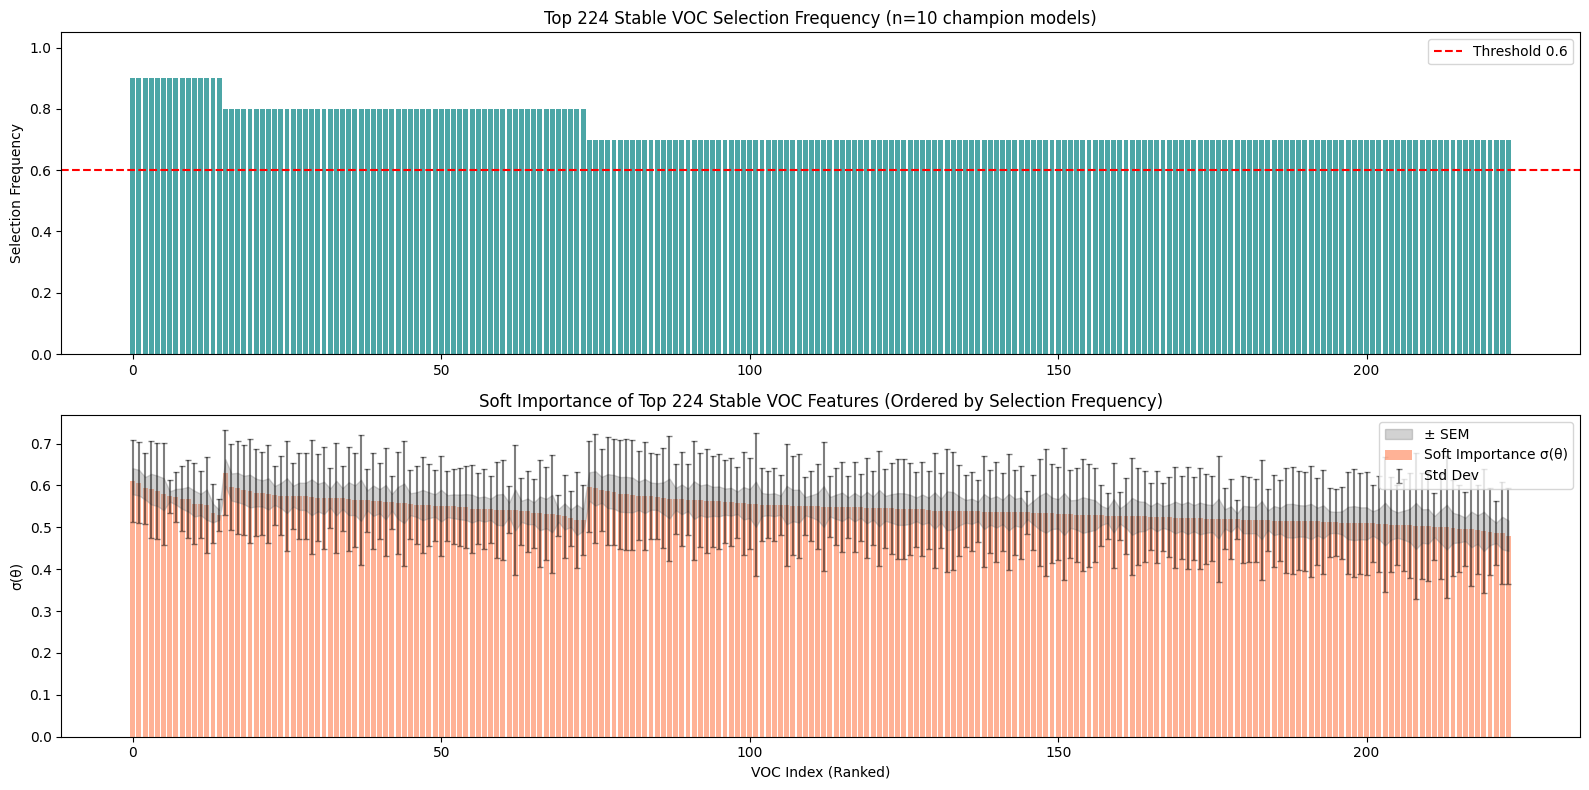

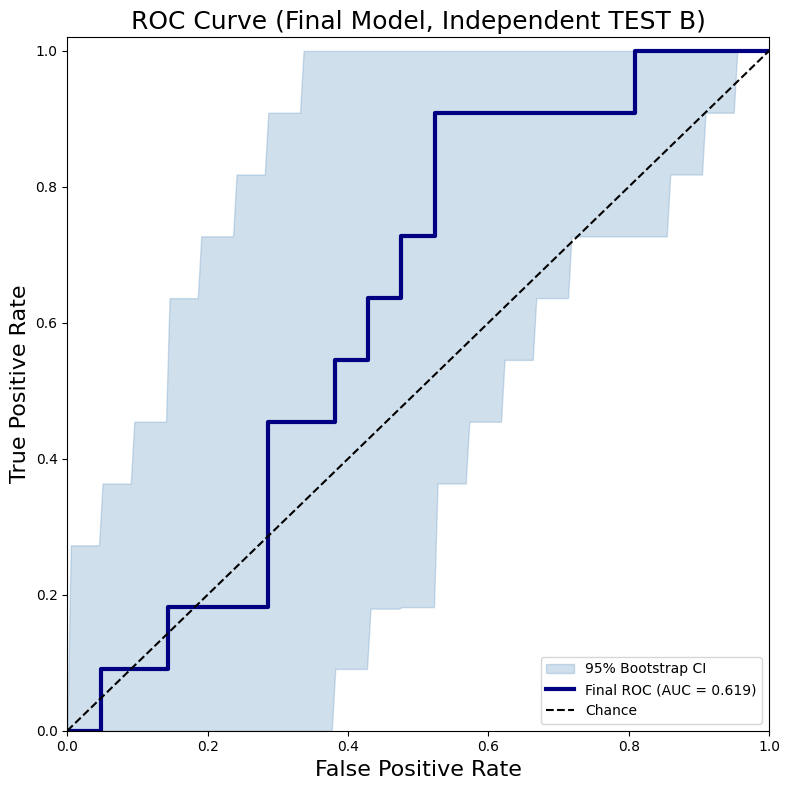

TEST AUC = 0.6190
TEST AUC 95% Bootstrap CI = [0.4241, 0.8053]


FINAL INDEPENDENT TEST B REPORT
测试样本数: 32
稳定特征数: 224
开发集确定分类阈值: 0.50
10 次划分 × 10 个模型 = 100 个候选模型
----------------------------------------------------------------------
Sensitivity    0.0000
Specificity    1.0000
PPV            0.0000
NPV            0.6562
Accuracy       0.6562
F1             0.0000
AUC            0.6190
----------------------------------------------------------------------
Confusion Matrix:
[[21  0]
 [11  0]]


In [17]:
best_result_table1_cnn_same_data = experiment(

    './data/voc_dataset_table1_1+2_vs_3_bpd.mat',

    './result/table1_cnn_same_data_10x10/all_masks.pt',

    num_cluster=3,

    experiment_repeats=10,
    repeats=10,

    epochs=30,

    sparsity_lambda=1e-2,

    temp_start=1.0,
    temp_end=0.3,

    seed=42,

    panel_threshold=0.6,

    roc_bootstrap=1000,

    threshold_objective='f1_acc',

    positive_class_weight=1.0,
)

In [16]:
import torch

test_mask = torch.zeros(3, 1692)

idx = torch.arange(1692)

test_mask[idx % 3, idx] = 1.0

test_model = MultiView(
    k_mean_mask=test_mask,
    num_blocks=4,
    head_dim=256,
    num_class=2,
    temperature=1.0
).to(DEVICE, dtype=DTYPE)

test_x = torch.randn(
    4, 1692,
    device=DEVICE,
    dtype=DTYPE
)

outputs, mask = test_model(test_x)

outputs.sum().backward()

print("输出形状：", outputs.shape)
print("Mask 形状：", mask.shape)

print(
    "CNN 梯度：",
    test_model.cnn_classifier.features[0].weight.grad is not None
)

print(
    "特征选择梯度：",
    any(
        p.grad is not None
        for p in test_model.logist.parameters()
    )
)

输出形状： torch.Size([4, 2])
Mask 形状： torch.Size([1692])
CNN 梯度： True
特征选择梯度： True


总样本数: 159
总 VOC 数: 1692
类别: [0, 1]
开发集 A: 127
独立测试集 B: 32


开始执行唯一一次 K-means / feature clustering
K-means 已完成，后续所有实验固定使用同一 View 划分。


开发集随机划分 1/10
A'(1) 训练样本: 95
B'(1) 验证样本: 32

Split 01 | Model 01/10 | seed=100042
Val Accuracy = 0.6875, AUC = 0.5628, F1 = 0.3750

Split 01 | Model 02/10 | seed=100043
Val Accuracy = 0.6875, AUC = 0.5281, F1 = 0.2857

Split 01 | Model 03/10 | seed=100044
Val Accuracy = 0.6562, AUC = 0.6407, F1 = 0.0000

Split 01 | Model 04/10 | seed=100045
Val Accuracy = 0.6562, AUC = 0.4589, F1 = 0.0000

Split 01 | Model 05/10 | seed=100046
Val Accuracy = 0.6562, AUC = 0.5671, F1 = 0.0000

Split 01 | Model 06/10 | seed=100047
Val Accuracy = 0.6562, AUC = 0.7359, F1 = 0.0000

Split 01 | Model 07/10 | seed=100048
Val Accuracy = 0.6562, AUC = 0.5411, F1 = 0.0000

Split 01 | Model 08/10 | seed=100049
Val Accuracy = 0.6875, AUC = 0.4719, F1 = 0.2857

Split 01 | Model 09/10 | seed=100050
Val Accuracy = 0.6875, AUC = 0.5368, F1 = 0.2857

Split 01 | Model 10/10 | seed=100051
Va

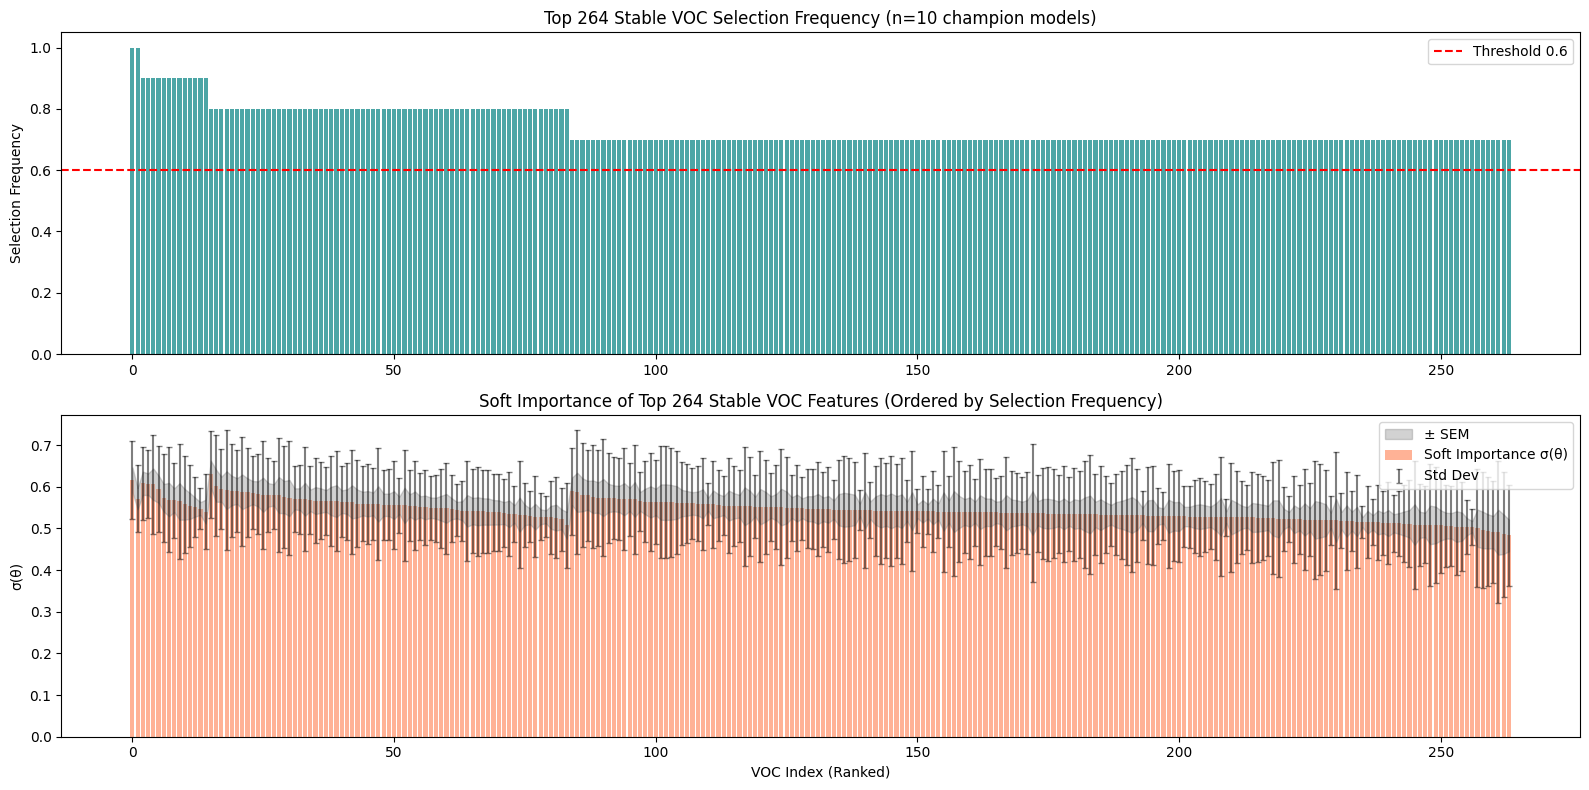

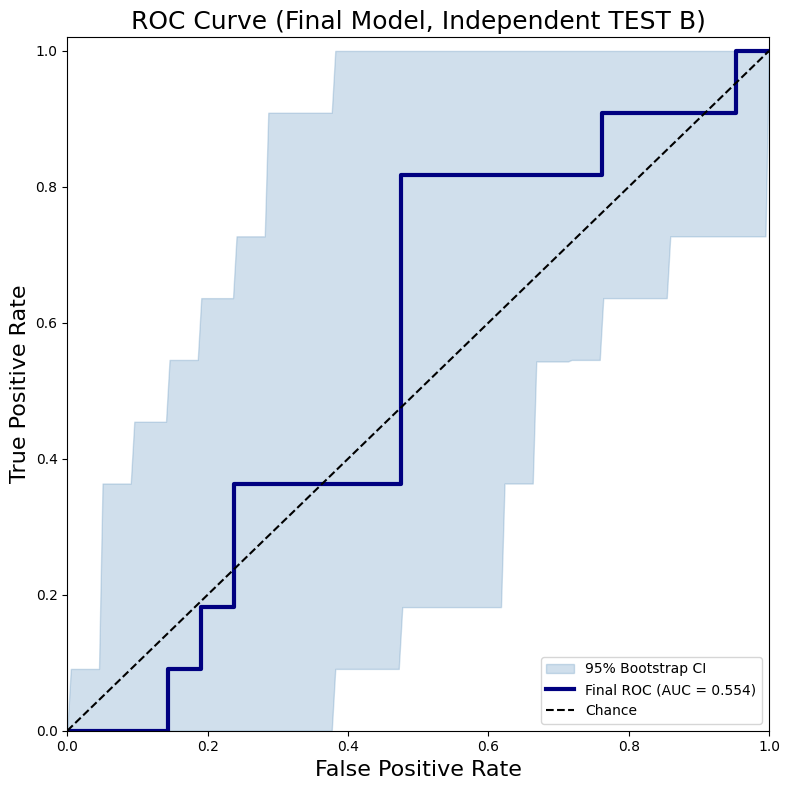

TEST AUC = 0.5541
TEST AUC 95% Bootstrap CI = [0.3463, 0.7577]


FINAL INDEPENDENT TEST B REPORT
测试样本数: 32
稳定特征数: 264
开发集确定分类阈值: 0.47
10 次划分 × 10 个模型 = 100 个候选模型
----------------------------------------------------------------------
Sensitivity    0.0000
Specificity    0.9524
PPV            0.0000
NPV            0.6452
Accuracy       0.6250
F1             0.0000
AUC            0.5541
----------------------------------------------------------------------
Confusion Matrix:
[[20  1]
 [11  0]]


In [14]:

# ============================================================
# BPD-CNN 正式实验
# 表一：0.5 阈值处理 + 全零特征删除
# ============================================================

best_result_table1_threshold05_cnn = experiment(

    './data/voc_dataset_table1_1+2_vs_3_threshold05_maskzero_removed.mat',

    './result/table1_threshold05_cnn_10x10/all_masks.pt',

    num_cluster=3,

    experiment_repeats=10,
    repeats=10,

    epochs=30,

    sparsity_lambda=1e-2,

    temp_start=1.0,
    temp_end=0.3,

    seed=42,

    panel_threshold=0.6,

    roc_bootstrap=1000,

    threshold_objective='f1_acc',

    positive_class_weight=1.0,
)


In [12]:
import importlib
import modules

# 重新加载修改后的 modules.py
importlib.reload(modules)

# 更新当前 Notebook 中的 MultiView 类
from modules import *

print("CNN 模型加载成功")

CNN 模型加载成功


In [13]:
# ============================================================
# CNN 模型前向传播与反向传播测试
# ============================================================

# 构建测试用 K-means mask
test_mask = torch.zeros(3, 1692)

feature_indices = torch.arange(1692)

test_mask[
    feature_indices % 3,
    feature_indices
] = 1.0

# 创建 CNN 版本 MultiView
test_model = MultiView(
    k_mean_mask=test_mask,
    num_blocks=8,
    head_dim=128,
    num_class=2,
    temperature=1.0
).to(DEVICE, dtype=DTYPE)

# 模拟输入
test_x = torch.randn(
    4,
    1692,
    device=DEVICE,
    dtype=DTYPE
)

# 前向传播
test_outputs, test_feature_mask = test_model(test_x)

# 反向传播
test_loss = test_outputs.sum()
test_loss.backward()

print("CNN 前向传播测试成功")
print("输入形状：", test_x.shape)
print("输出形状：", test_outputs.shape)
print("Mask 形状：", test_feature_mask.shape)
print(
    "CNN 梯度是否正常：",
    test_model.cnn_classifier.features[0].weight.grad is not None
)

CNN 前向传播测试成功
输入形状： torch.Size([4, 1692])
输出形状： torch.Size([4, 2])
Mask 形状： torch.Size([1692])
CNN 梯度是否正常： True


In [7]:

# ============================================================
# 表一数据预处理：
# 1. 小于 0.5 的 VOC 数值置为 0
# 2. 删除所有样本中完全为 0 的 VOC 特征列
# ============================================================

import numpy as np
from scipy.io import loadmat, savemat

# 1. 读取原始表一数据
src = './data/voc_dataset_table1_1+2_vs_3_bpd.mat'

data = loadmat(src)

X = data['X'].copy()
y = data['y'].copy()

feat_names = data['feat_names'].reshape(-1)

print("=" * 60)
print("原始数据")
print("样本数：", X.shape[0])
print("VOC 数：", X.shape[1])

# 2. 小于 0.5 的数值置为 0
threshold = 0.5

X_processed = X.copy()
X_processed[X_processed < threshold] = 0

# 统计被置零的数值数量
changed_count = int(np.sum(X < threshold))

# 3. 删除全部样本中均为 0 的 VOC 列
zero_mask = np.all(X_processed == 0, axis=0)

removed_count = int(zero_mask.sum())

# 保留非全零特征
X_new = X_processed[:, ~zero_mask]
feat_names_new = feat_names[~zero_mask]

# 4. 更新特征编号
data['X'] = X_new
data['y'] = y

data['feat_names'] = feat_names_new.reshape(1, -1)

if 'feature_names' in data:
    data['feature_names'] = feat_names_new.reshape(1, -1)

if 'feature_ids' in data:
    ids = data['feature_ids'].reshape(-1)

    if len(ids) == X.shape[1]:
        data['feature_ids'] = ids[~zero_mask].reshape(1, -1)

# 5. 保存新数据
dst = (
    './data/'
    'voc_dataset_table1_1+2_vs_3_threshold05_maskzero_removed.mat'
)

savemat(
    dst,
    {
        k: v for k, v in data.items()
        if not k.startswith('__')
    }
)

# 6. 输出统计
print("=" * 60)
print("数据处理统计")
print("=" * 60)

print("原始 VOC 数：", X.shape[1])
print("小于 0.5 的数值数量：", changed_count)
print("删除的全零 VOC 数：", removed_count)
print("最终保留 VOC 数：", X_new.shape[1])
print("最终数据形状：", X_new.shape)

print("是否还存在小于 0.5 的数值：",
      np.any((X_new > 0) & (X_new < 0.5)))

print("是否还存在全零 VOC：",
      np.any(np.all(X_new == 0, axis=0)))

print("新文件保存位置：", dst)
print("=" * 60)


原始数据
样本数： 159
VOC 数： 1692
数据处理统计
原始 VOC 数： 1692
小于 0.5 的数值数量： 188
删除的全零 VOC 数： 0
最终保留 VOC 数： 1692
最终数据形状： (159, 1692)
是否还存在小于 0.5 的数值： False
是否还存在全零 VOC： False
新文件保存位置： ./data/voc_dataset_table1_1+2_vs_3_threshold05_maskzero_removed.mat


In [8]:
check = loadmat(
    './data/voc_dataset_table1_1+2_vs_3_threshold05_maskzero_removed.mat'
)

X_check = check['X']
y_check = check['y'].reshape(-1)

print("数据形状：", X_check.shape)
print("类别分布：", np.unique(y_check, return_counts=True))

print("是否存在小于0.5的非零值：",
      np.any((X_check > 0) & (X_check < 0.5)))

print("是否存在全零特征：",
      np.any(np.all(X_check == 0, axis=0)))

print("特征名称数量：",
      len(check['feat_names'].flatten()))

数据形状： (159, 1692)
类别分布： (array([0, 1], dtype=int32), array([106,  53]))
是否存在小于0.5的非零值： False
是否存在全零特征： False
特征名称数量： 1692


In [6]:

# ============================================================
# 实验二：删除全零 VOC 特征
# ============================================================

import os
import numpy as np
from scipy.io import loadmat, savemat

# 1. 读取上次完整的表一数据
src = './data/voc_dataset_table1_1+2_vs_3_bpd.mat'

data = loadmat(src)

X = data['X']
y = data['y']

# 2. 读取 VOC 名称
feat_names = data['feat_names'].reshape(-1)

# 3. 找出所有样本中完全为零的 VOC
zero_mask = np.all(X == 0, axis=0)

# 4. 保留非全零 VOC
X_new = X[:, ~zero_mask]
feat_names_new = feat_names[~zero_mask]

# 5. 统计
removed_count = int(zero_mask.sum())
remaining_count = X_new.shape[1]

print("=" * 60)
print("全零 VOC 删除统计")
print("=" * 60)

print("原始样本数：", X.shape[0])
print("原始 VOC 数：", X.shape[1])
print("删除全零 VOC 数：", removed_count)
print("保留 VOC 数：", remaining_count)
print("删除后数据形状：", X_new.shape)

# 6. 更新 MAT 数据
data['X'] = X_new
data['feat_names'] = feat_names_new.reshape(1, -1)

# 同步更新原来的特征名称字段
if 'feature_names' in data:
    data['feature_names'] = feat_names_new.reshape(1, -1)

# 如果存在特征编号，也同步筛选
if 'feature_ids' in data:
    ids = data['feature_ids']
    if ids.size == X.shape[1]:
        data['feature_ids'] = ids.reshape(-1)[~zero_mask].reshape(1, -1)

# 7. 保存新文件
dst = './data/voc_dataset_table1_1+2_vs_3_maskzero_removed.mat'

savemat(
    dst,
    {
        k: v for k, v in data.items()
        if not k.startswith('__')
    }
)

print("=" * 60)
print("新数据已保存：", dst)


全零 VOC 删除统计
原始样本数： 159
原始 VOC 数： 1692
删除全零 VOC 数： 0
保留 VOC 数： 1692
删除后数据形状： (159, 1692)
新数据已保存： ./data/voc_dataset_table1_1+2_vs_3_maskzero_removed.mat


In [4]:
print("experiment 函数是否加载：", callable(experiment))

experiment 函数是否加载： True


总样本数: 159
总 VOC 数: 1692
类别: [0, 1]
开发集 A: 127
独立测试集 B: 32


开始执行唯一一次 K-means / feature clustering
K-means 已完成，后续所有实验固定使用同一 View 划分。


开发集随机划分 1/10
A'(1) 训练样本: 95
B'(1) 验证样本: 32

Split 01 | Model 01/10 | seed=100042
Val Accuracy = 0.6875, AUC = 0.6320, F1 = 0.5000

Split 01 | Model 02/10 | seed=100043
Val Accuracy = 0.7812, AUC = 0.7251, F1 = 0.6316

Split 01 | Model 03/10 | seed=100044
Val Accuracy = 0.6875, AUC = 0.6537, F1 = 0.5455

Split 01 | Model 04/10 | seed=100045
Val Accuracy = 0.6875, AUC = 0.5887, F1 = 0.3750

Split 01 | Model 05/10 | seed=100046
Val Accuracy = 0.6562, AUC = 0.6515, F1 = 0.5600

Split 01 | Model 06/10 | seed=100047
Val Accuracy = 0.6875, AUC = 0.6104, F1 = 0.4444

Split 01 | Model 07/10 | seed=100048
Val Accuracy = 0.6250, AUC = 0.5195, F1 = 0.2500

Split 01 | Model 08/10 | seed=100049
Val Accuracy = 0.8125, AUC = 0.7273, F1 = 0.6250

Split 01 | Model 09/10 | seed=100050
Val Accuracy = 0.7187, AUC = 0.6558, F1 = 0.5263

Split 01 | Model 10/10 | seed=100051
Va

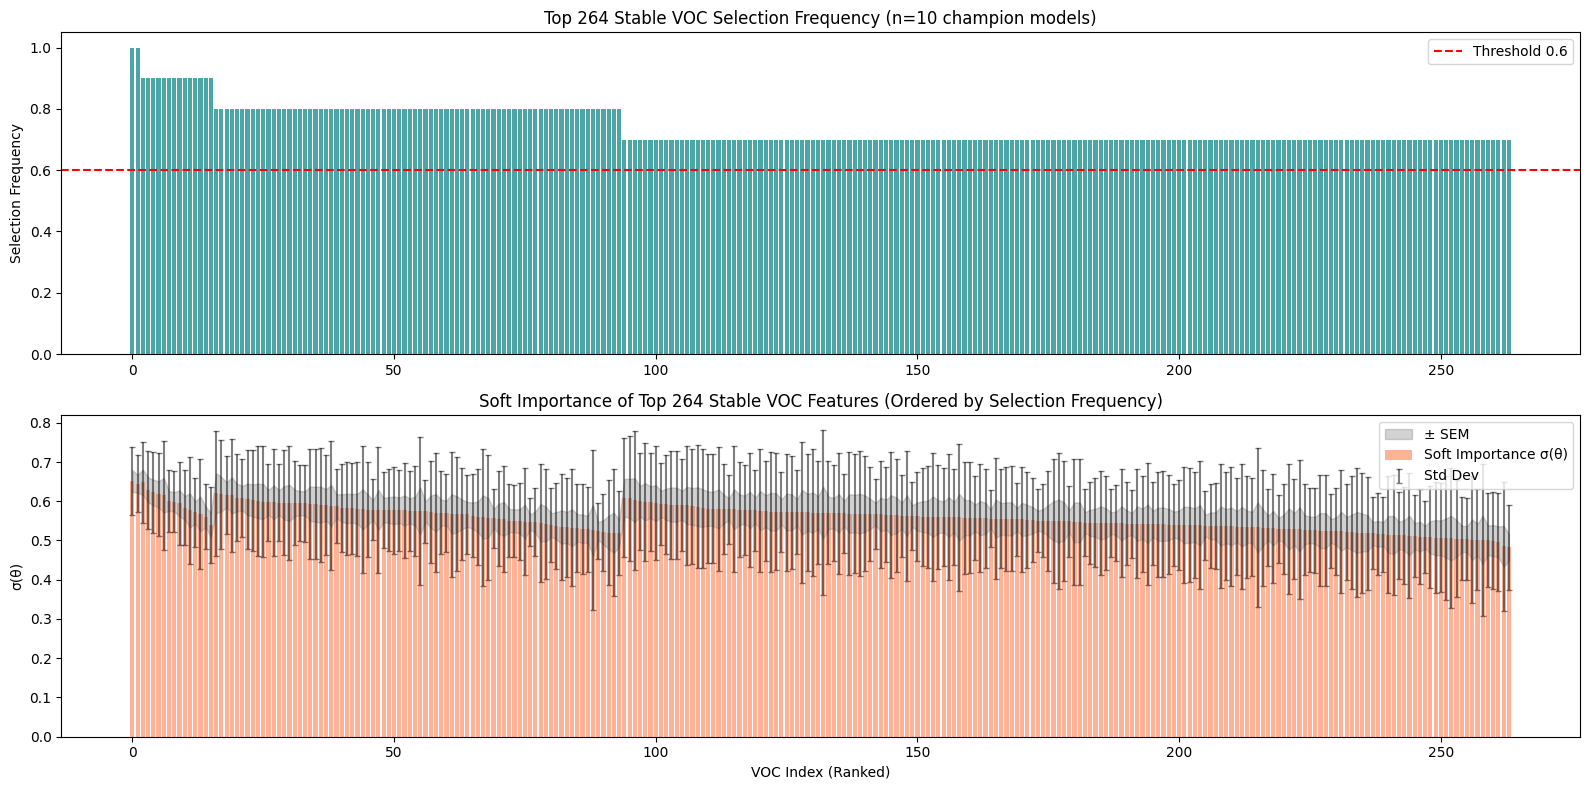

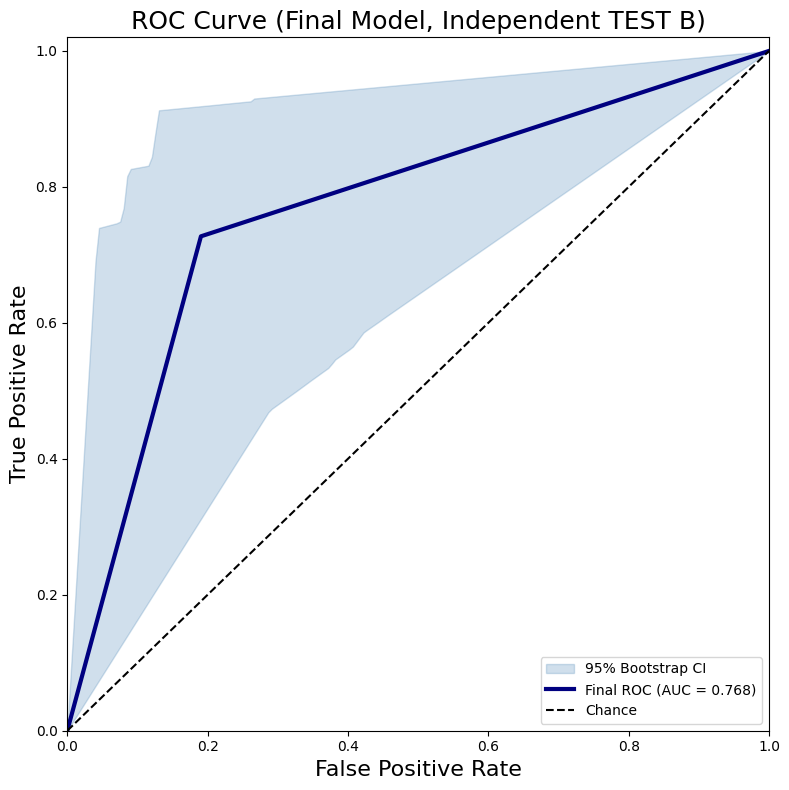

TEST AUC = 0.7684
TEST AUC 95% Bootstrap CI = [0.6060, 0.9069]


FINAL INDEPENDENT TEST B REPORT
测试样本数: 32
稳定特征数: 264
开发集确定分类阈值: 0.05
10 次划分 × 10 个模型 = 100 个候选模型
----------------------------------------------------------------------
Sensitivity    0.7273
Specificity    0.8095
PPV            0.6667
NPV            0.8500
Accuracy       0.7812
F1             0.6957
AUC            0.7684
----------------------------------------------------------------------
Confusion Matrix:
[[17  4]
 [ 3  8]]


In [5]:
best_result_table1 = experiment(
    './data/voc_dataset_table1_1+2_vs_3_bpd.mat',
    './result/table1_10x10/all_masks.pt',

    num_cluster=3,

    experiment_repeats=10,
    repeats=10,

    epochs=30,

    sparsity_lambda=1e-2,

    temp_start=1.0,
    temp_end=0.3,

    seed=42,

    panel_threshold=0.6,

    roc_bootstrap=1000,

    threshold_objective='f1_acc',

    positive_class_weight=1.0,
)

In [ ]:
best_result = experiment(
    './data/voc_dataset_1+2_vs_3.mat',
    './result/val_threshold_10x10_recovered/all_masks.pt',

    num_cluster=3,

    experiment_repeats=10,
    repeats=10,

    epochs=30,

    sparsity_lambda=1e-2,

    temp_start=1.0,
    temp_end=0.3,

    seed=42,

    # >60% 稳定 VOC
    panel_threshold=0.6,

    roc_bootstrap=1000,

    # 保留验证集阈值优化
    threshold_objective='f1_acc',

    # 不进行类别加权
    positive_class_weight=1.0,
)

总样本数: 159
总 VOC 数: 779
类别: [0, 1]
开发集 A: 127
独立测试集 B: 32


开始执行唯一一次 K-means / feature clustering
K-means 已完成，后续所有实验固定使用同一 View 划分。


开发集随机划分 1/10
A'(1) 训练样本: 95
B'(1) 验证样本: 32

Split 01 | Model 01/10 | seed=100042
Val Accuracy = 0.6562, AUC = 0.4459, F1 = 0.0000

Split 01 | Model 02/10 | seed=100043
Val Accuracy = 0.7500, AUC = 0.7316, F1 = 0.5556

Split 01 | Model 03/10 | seed=100044
Val Accuracy = 0.6562, AUC = 0.4329, F1 = 0.0000

Split 01 | Model 04/10 | seed=100045
Val Accuracy = 0.6562, AUC = 0.4675, F1 = 0.0000

Split 01 | Model 05/10 | seed=100046
Val Accuracy = 0.6875, AUC = 0.3290, F1 = 0.1667

Split 01 | Model 06/10 | seed=100047
Val Accuracy = 0.6875, AUC = 0.5281, F1 = 0.1667

Split 01 | Model 07/10 | seed=100048
Val Accuracy = 0.6562, AUC = 0.3723, F1 = 0.0000

Split 01 | Model 08/10 | seed=100049
Val Accuracy = 0.6562, AUC = 0.4242, F1 = 0.0000

Split 01 | Model 09/10 | seed=100050
Val Accuracy = 0.6562, AUC = 0.6017, F1 = 0.3529

Split 01 | Model 10/10 | seed=100051
Val

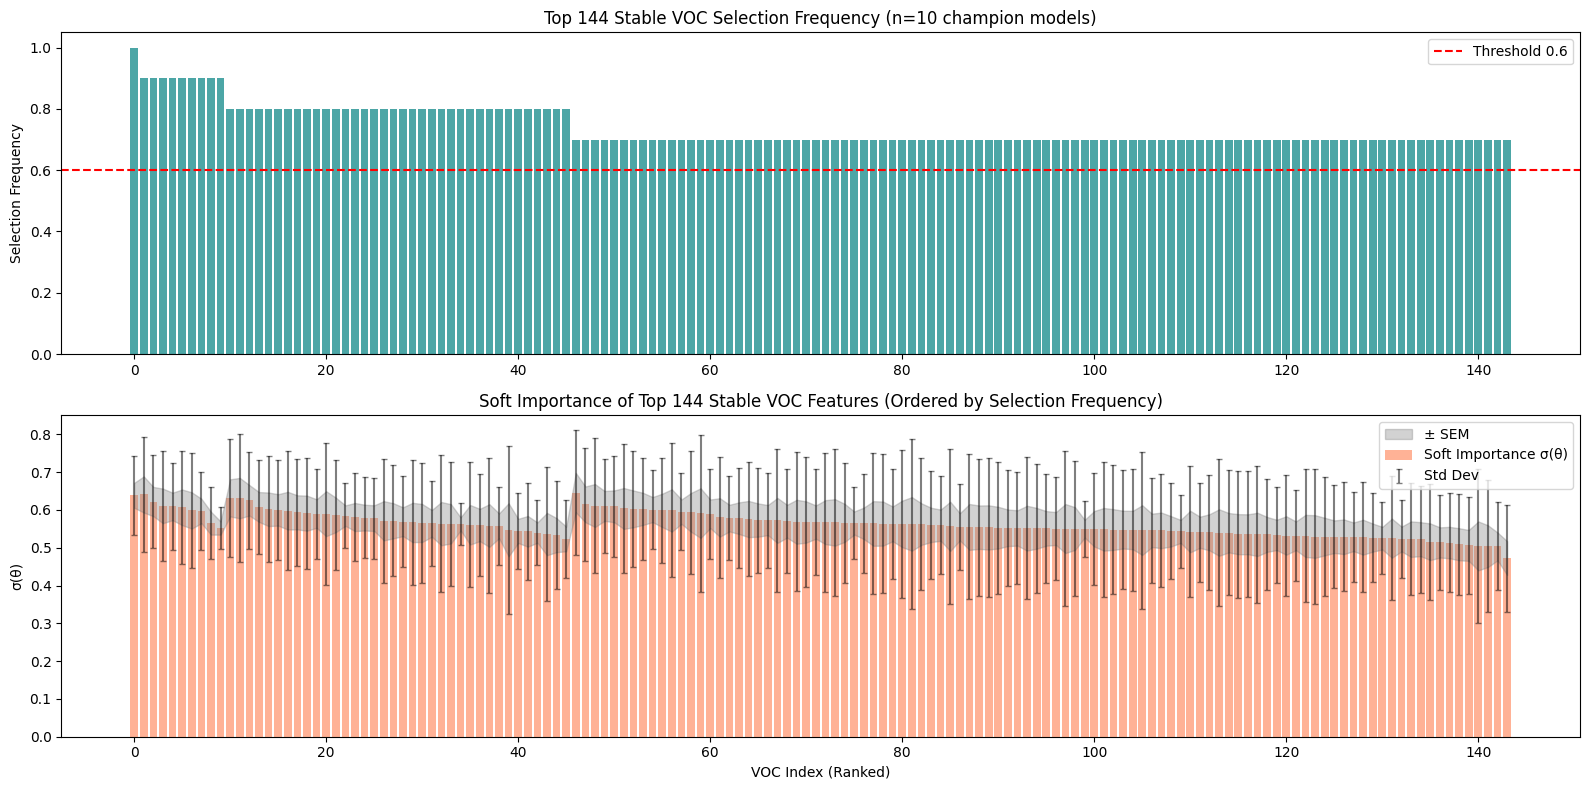

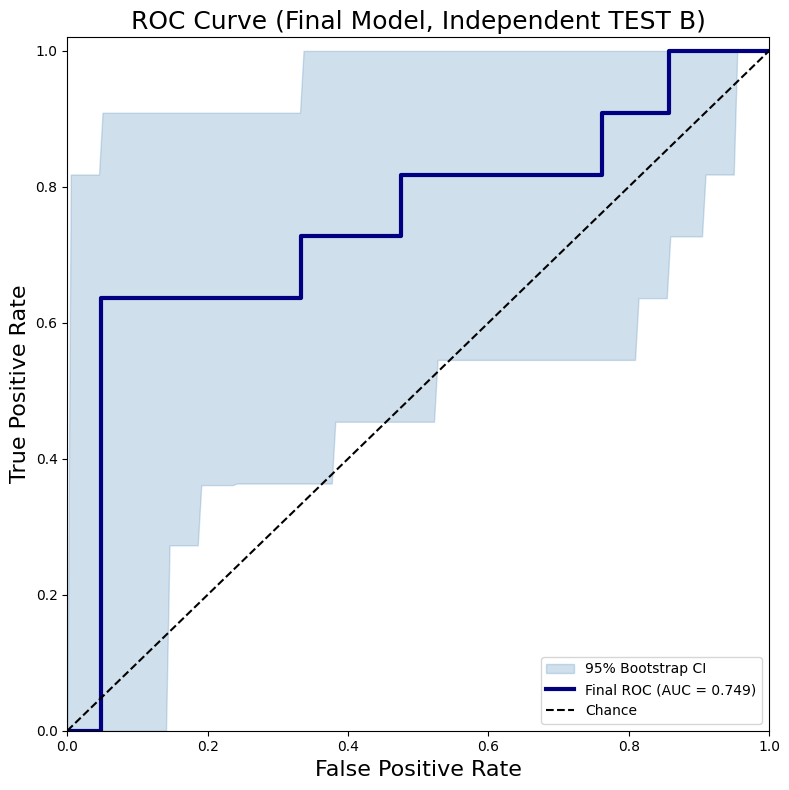

TEST AUC = 0.7489
TEST AUC 95% Bootstrap CI = [0.5325, 0.9307]


FINAL INDEPENDENT TEST B REPORT
测试样本数: 32
稳定特征数: 144
开发集确定分类阈值: 0.50
10 次划分 × 10 个模型 = 100 个候选模型
----------------------------------------------------------------------
Sensitivity    0.4545
Specificity    0.9524
PPV            0.8333
NPV            0.7692
Accuracy       0.7812
F1             0.5882
AUC            0.7489
----------------------------------------------------------------------
Confusion Matrix:
[[20  1]
 [ 6  5]]


In [3]:
best_result_maskzero_removed = experiment(
    './data/voc_dataset_1+2_vs_3_maskzero_removed.mat',

    './result/val_threshold_10x10_maskzero_removed/all_masks.pt',

    num_cluster=3,

    experiment_repeats=10,
    repeats=10,

    epochs=30,

    sparsity_lambda=1e-2,

    temp_start=1.0,
    temp_end=0.3,

    seed=42,

    panel_threshold=0.6,

    roc_bootstrap=1000,

    threshold_objective='f1_acc',

    positive_class_weight=1.0,
)

In [1]:
from scipy.io import loadmat
import numpy as np

data = loadmat(
    './data/voc_dataset_table1_1+2_vs_3.mat'
)

X = data['X']
y = data['y'].reshape(-1)

print("数据形状：", X.shape)
print("标签形状：", y.shape)
print("类别分布：", np.unique(y, return_counts=True))
print("是否存在 NaN：", np.isnan(X).any())
print("是否存在 Inf：", np.isinf(X).any())

数据形状： (159, 1692)
标签形状： (159,)
类别分布： (array([0, 1], dtype=int32), array([106,  53]))
是否存在 NaN： False
是否存在 Inf： False


In [2]:
from scipy.io import loadmat, savemat

# 读取原始 MAT 文件
src = './data/voc_dataset_table1_1+2_vs_3.mat'

data = loadmat(src)

# 补充 BPD 代码要求的字段名称
data['feat_names'] = data['feature_names']

# 保存为新的文件，不覆盖原文件
dst = './data/voc_dataset_table1_1+2_vs_3_bpd.mat'

savemat(
    dst,
    {
        k: v for k, v in data.items()
        if not k.startswith('__')
    }
)

# 检查
check = loadmat(dst)

print("数据形状：", check['X'].shape)
print("标签形状：", check['y'].shape)
print("特征名称数量：", len(check['feat_names'].flatten()))
print("是否存在 feat_names：", 'feat_names' in check)

数据形状： (159, 1692)
标签形状： (159, 1)
特征名称数量： 1692
是否存在 feat_names： True
